# Propane Dehydrogenation (PDH) Catalyst Screening & Deactivation Modeling via Physics-Informed ML
**Author**: Aditya001-max (<kaushikadityaraj001@gmail.com>)
**GitHub**: [https://github.com/Aditya001-max](https://github.com/Aditya001-max)
---
This notebook implements an end-to-end framework for predicting catalytic conversion, selectivity, yield, and coke fouling under kinetic and thermodynamic constraints.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import time as time
from mpl_toolkits.mplot3d import Axes3D
plt.rcParams['font.family'] = 'DejaVu Sans'

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib.font_manager")



In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
!pip install openpyxl

In [ ]:
!ls /content/gdrive/MyDrive/algo/


'AZ_Premium_Cohort10_Sessions (1).xlsx'
 PDH_Catalyst_Dataset_3000_with_Coke.xlsx


In [ ]:
import pandas as pd

data_path = '/content/gdrive/MyDrive/algo/PDH_Catalyst_Dataset_3000_with_Coke.xlsx'
df = pd.read_excel(data_path, engine='openpyxl')

display(df.head())

,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Catalyst,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Dopants_Pt-M,Pore_volume_cm3_g,Reduction_Temperature_TPR_C,Conversion_%,Selectivity_%,Propene_yield%,Coke_deposition_wt%
0,0.5,570,5.0,0.05,Pt-Sn/γ-Al₂O₃,170.0,11.70,0.480,Sn,0.4610,377,46.52,89.99,41.86,0.068
1,3.0,600,5.0,0.10,Pt-Sn/γ-Al₂O₃,166.7,6.86,0.317,Sn,0.4432,473,52.18,91.20,47.59,1.018
2,1.0,570,1.5,0.08,Pt-Sn/γ-Al₂O₃,140.6,6.14,0.420,Sn,0.4155,358,44.35,91.68,40.66,0.412
3,50.0,630,5.0,0.25,Pt-Sn/γ-Al₂O₃,177.3,11.16,0.435,Sn,0.4497,352,52.48,84.90,44.55,2.338
4,20.0,550,1.0,0.20,Pt-Sn/γ-Al₂O₃,194.7,8.64,0.449,Sn,0.3268,356,43.57,91.58,39.90,1.899


In [ ]:
print(f"Dataset shape: {df.shape}")

Dataset shape: (3000, 15)


In [ ]:
df.head()

,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Catalyst,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Dopants_Pt-M,Pore_volume_cm3_g,Reduction_Temperature_TPR_C,Conversion_%,Selectivity_%,Propene_yield%,Coke_deposition_wt%
0,0.5,570,5.0,0.05,Pt-Sn/γ-Al₂O₃,170.0,11.70,0.480,Sn,0.4610,377,46.52,89.99,41.86,0.068
1,3.0,600,5.0,0.10,Pt-Sn/γ-Al₂O₃,166.7,6.86,0.317,Sn,0.4432,473,52.18,91.20,47.59,1.018
2,1.0,570,1.5,0.08,Pt-Sn/γ-Al₂O₃,140.6,6.14,0.420,Sn,0.4155,358,44.35,91.68,40.66,0.412
3,50.0,630,5.0,0.25,Pt-Sn/γ-Al₂O₃,177.3,11.16,0.435,Sn,0.4497,352,52.48,84.90,44.55,2.338
4,20.0,550,1.0,0.20,Pt-Sn/γ-Al₂O₃,194.7,8.64,0.449,Sn,0.3268,356,43.57,91.58,39.90,1.899


Current Skewness of 'Propene_yield%': -0.214


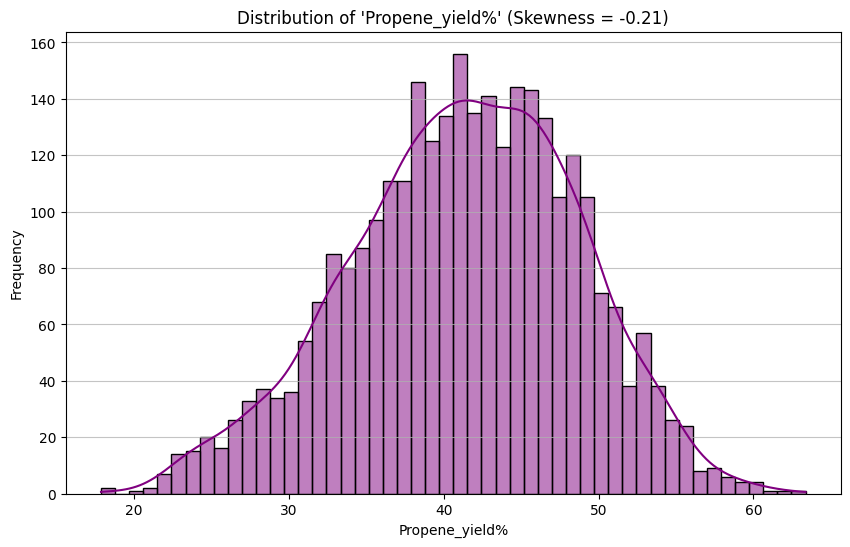

In [ ]:
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns
current_propene_yield_skew = skew(df['Propene_yield%'])
print(f"Current Skewness of 'Propene_yield%': {current_propene_yield_skew:.3f}")
plt.figure(figsize=(10, 6))
sns.histplot(df['Propene_yield%'], bins=50, kde=True, color='purple')
plt.title(f"Distribution of 'Propene_yield%' (Skewness = {current_propene_yield_skew:.2f})")
plt.xlabel('Propene_yield%')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

Skewness of numerical features:
Surface_BET_m2_g                1.586718
Coke_deposition_wt%             1.277127
Pt_loading_wt%                  1.162762
Pore_volume_cm3_g               1.052239
time_of_reaction_h              1.010667
Propane_H2_ratio                0.395663
Pore_size_nm                    0.223300
Partial_pressure_propane_bar    0.157787
temperature_C                   0.141509
Reduction_Temperature_TPR_C    -0.185678
Conversion_%                   -0.207230
Propene_yield%                 -0.214002
Selectivity_%                  -0.344804
dtype: float64


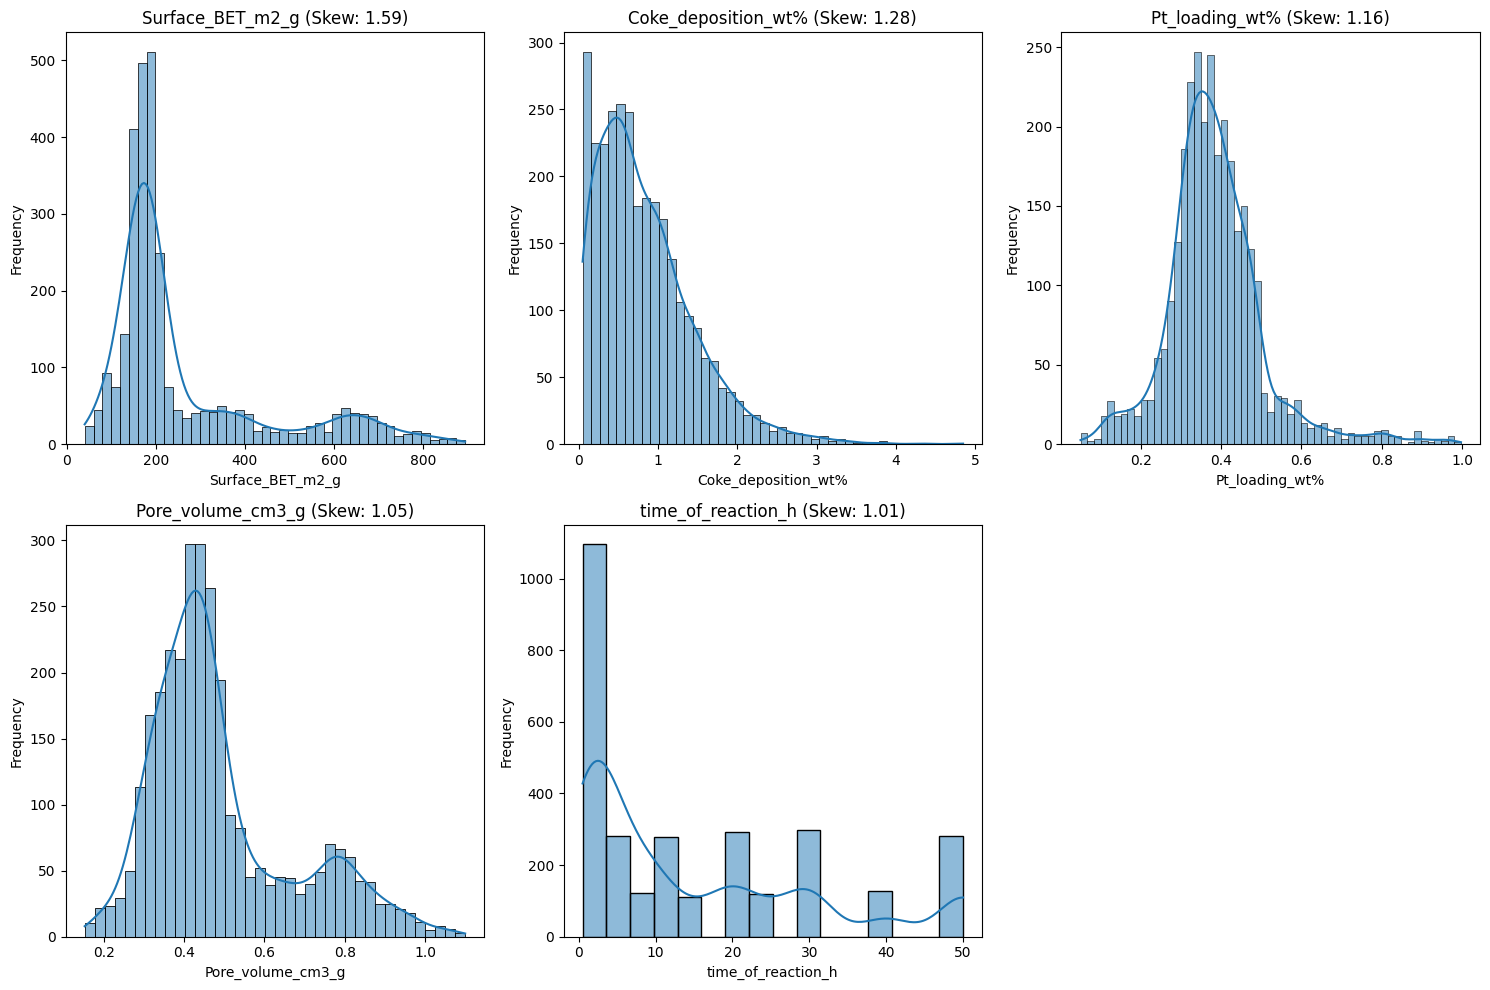

In [ ]:
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
skewed_features = df[numerical_cols].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
print("Skewness of numerical features:")
print(skewed_features)
highly_skewed = skewed_features[skewed_features > 0.75].index

if not highly_skewed.empty:
    plt.figure(figsize=(15, 10))
    for i, feature in enumerate(highly_skewed):
        plt.subplot(int(np.ceil(len(highly_skewed)/3)), 3, i + 1)
        sns.histplot(df[feature], kde=True)
        plt.title(f'{feature} (Skew: {skewed_features[feature]:.2f})')
        plt.xlabel(feature)
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
else:
    print("No highly skewed numerical features found (skewness > 0.75).")

SKewness analysis


Applying log1p transformation to: ['Surface_BET_m2_g', 'Coke_deposition_wt%', 'Pt_loading_wt%', 'Pore_volume_cm3_g', 'time_of_reaction_h']

Skewness of numerical features after log1p transformation:
Pore_volume_cm3_g               0.817459
Surface_BET_m2_g                0.618676
Pt_loading_wt%                  0.608573
Coke_deposition_wt%             0.403397
Propane_H2_ratio                0.395663
Pore_size_nm                    0.223300
Partial_pressure_propane_bar    0.157787
temperature_C                   0.141509
time_of_reaction_h             -0.038822
Reduction_Temperature_TPR_C    -0.185678
Conversion_%                   -0.207230
Propene_yield%                 -0.214002
Selectivity_%                  -0.344804
dtype: float64


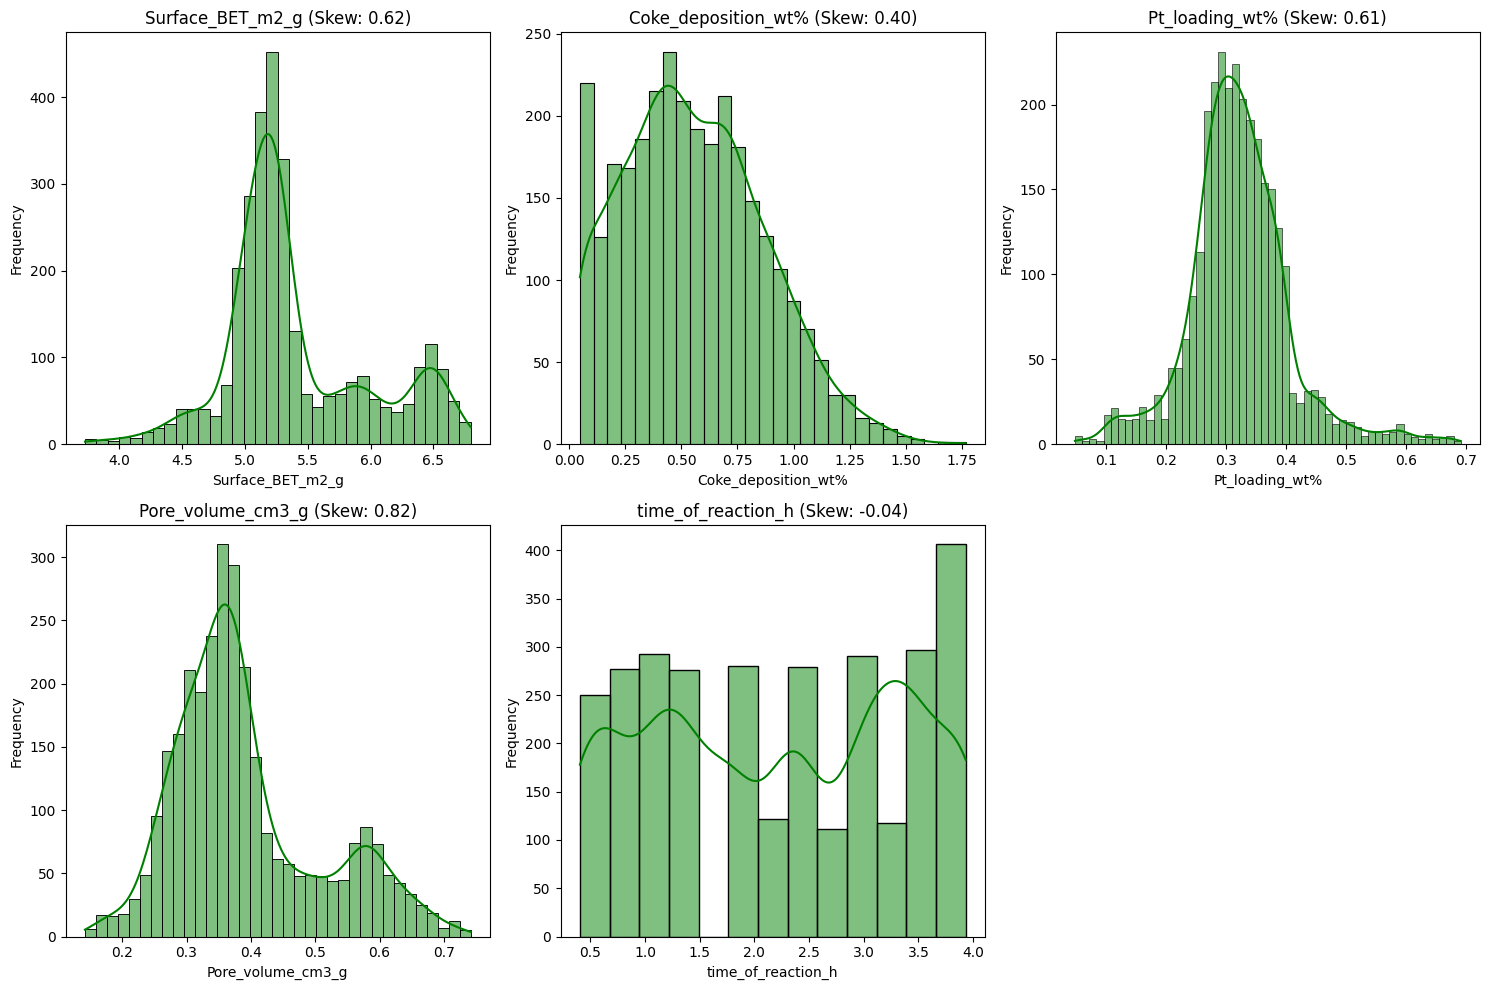

In [ ]:
import numpy as np
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns
df_processed = df.copy()

numerical_cols = df_processed.select_dtypes(include=np.number).columns.tolist()
skewed_features_initial = df_processed[numerical_cols].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)

highly_skewed_to_transform = skewed_features_initial[skewed_features_initial > 0.75].index.tolist()

print(f"Applying log1p transformation to: {highly_skewed_to_transform}")

for feature in highly_skewed_to_transform:

    df_processed[feature] = np.log1p(df_processed[feature])


skewed_features_after_transform = df_processed[numerical_cols].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)

print("\nSkewness of numerical features after log1p transformation:")
print(skewed_features_after_transform)

if highly_skewed_to_transform: # Corrected from .empty
    plt.figure(figsize=(15, 10))
    for i, feature in enumerate(highly_skewed_to_transform):
        plt.subplot(int(np.ceil(len(highly_skewed_to_transform)/3)), 3, i + 1)
        sns.histplot(df_processed[feature], kde=True, color='green')
        plt.title(f'{feature} (Skew: {skewed_features_after_transform[feature]:.2f})')
        plt.xlabel(feature)
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
else:
    print("No highly skewed numerical features required transformation.")

### 3.2.2 Feature Scaling (Min-Max Normalization)


$$X_{normalized} = \frac{X - X_{min}}{X_{max} - X_{min}}$$


In [ ]:
# from sklearn.preprocessing import MinMaxScaler
# import numpy as np
# from scipy.stats import skew

# df_processed = df.copy()

# numerical_cols = df_processed.select_dtypes(include=np.number).columns.tolist()
# skewed_features_initial = df_processed[numerical_cols].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
# highly_skewed_to_transform = skewed_features_initial[skewed_features_initial > 0.75].index.tolist()

# for feature in highly_skewed_to_transform:
#     df_processed[feature] = np.log1p(df_processed[feature])
# df_processed = inject_physics_features(df_processed)
# numerical_cols = df_processed.select_dtypes(include=np.number).columns.tolist()
# scaler_pre = MinMaxScaler()
# df_processed[numerical_cols] = scaler_pre.fit_transform(df_processed[numerical_cols])

# print("DataFrame after log1p transformation and physics feature injection (first 5 rows):")
# display(df_processed.head())

In [ ]:
import pandas as pd

categorical_cols = df_processed.select_dtypes(include='object').columns.tolist()

print(f"Categorical columns to encode: {categorical_cols}")

df_processed = pd.get_dummies(df_processed, columns=categorical_cols, drop_first=True)

print("\nDataFrame after One-Hot Encoding (first 5 rows):")
display(df_processed.head())
print(f"New shape of DataFrame: {df_processed.shape}")

Categorical columns to encode: ['Catalyst', 'Dopants_Pt-M']

DataFrame after One-Hot Encoding (first 5 rows):


,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Pore_volume_cm3_g,Reduction_Temperature_TPR_C,Conversion_%,...,"Dopants_Pt-M_Sn,La","Dopants_Pt-M_Sn,Li","Dopants_Pt-M_Sn,Mg","Dopants_Pt-M_Sn,Mn","Dopants_Pt-M_Sn,Na","Dopants_Pt-M_Sn,Pb","Dopants_Pt-M_Sn,Sr","Dopants_Pt-M_Sn,Zn",Dopants_Pt-M_V,Dopants_Pt-M_Zn
0,0.405465,570,5.0,0.05,5.141664,11.70,0.392042,0.379121,377,46.52,...,False,False,False,False,False,False,False,False,False,False
1,1.386294,600,5.0,0.10,5.122177,6.86,0.275356,0.366863,473,52.18,...,False,False,False,False,False,False,False,False,False,False
2,0.693147,570,1.5,0.08,4.953006,6.14,0.350657,0.347483,358,44.35,...,False,False,False,False,False,False,False,False,False,False
3,3.931826,630,5.0,0.25,5.183468,11.16,0.361165,0.371357,352,52.48,...,False,False,False,False,False,False,False,False,False,False
4,3.044522,550,1.0,0.20,5.276583,8.64,0.370874,0.282770,356,43.57,...,False,False,False,False,False,False,False,False,False,False


New shape of DataFrame: (3000, 100)


### 3.3.1 Handling Missing Values & 3.3.2 Median Imputation


In [ ]:

missing_values = df_processed.isnull().sum()
missing_values = missing_values[missing_values > 0]

print("Missing values before imputation:")
print(missing_values)

if not missing_values.empty:

    for col in missing_values.index:
        if pd.api.types.is_numeric_dtype(df_processed[col]):
            median_val = df_processed[col].median()
            df_processed[col].fillna(median_val, inplace=True)
            print(f"Imputed column '{col}' with median: {median_val}")
        else:
            print(f"Column '{col}' is not numeric, skipping median imputation.")


    missing_values_after = df_processed.isnull().sum()
    missing_values_after = missing_values_after[missing_values_after > 0]
    if missing_values_after.empty:
        print("\nAll missing values successfully imputed.")
    else:
        print("\nRemaining missing values after imputation:")
        print(missing_values_after)
else:
    print("\nNo missing values found in the dataset.")

print("\nDataFrame info after preprocessing:")
df_processed.info()


Missing values before imputation:
Series([], dtype: int64)

No missing values found in the dataset.

DataFrame info after preprocessing:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 100 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   time_of_reaction_h            3000 non-null   float64
 1   temperature_C                 3000 non-null   int64  
 2   Propane_H2_ratio              3000 non-null   float64
 3   Partial_pressure_propane_bar  3000 non-null   float64
 4   Surface_BET_m2_g              3000 non-null   float64
 5   Pore_size_nm                  3000 non-null   float64
 6   Pt_loading_wt%                3000 non-null   float64
 7   Pore_volume_cm3_g             3000 non-null   float64
 8   Reduction_Temperature_TPR_C   3000 non-null   int64  
 9   Conversion_%                  3000 non-null   float64
 10  Selectivity_%                 3000 non-nul

## Exploratory Data Analysis (EDA) Process


**1. Initial Data Inspection**

DataFrame Information (after preprocessing):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 100 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   time_of_reaction_h            3000 non-null   float64
 1   temperature_C                 3000 non-null   int64  
 2   Propane_H2_ratio              3000 non-null   float64
 3   Partial_pressure_propane_bar  3000 non-null   float64
 4   Surface_BET_m2_g              3000 non-null   float64
 5   Pore_size_nm                  3000 non-null   float64
 6   Pt_loading_wt%                3000 non-null   float64
 7   Pore_volume_cm3_g             3000 non-null   float64
 8   Reduction_Temperature_TPR_C   3000 non-null   int64  
 9   Conversion_%                  3000 non-null   float64
 10  Selectivity_%                 3000 non-null   float64
 11  Propene_yield%                3000 non-null

,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Pore_volume_cm3_g,Reduction_Temperature_TPR_C,Conversion_%,Selectivity_%,Propene_yield%,Coke_deposition_wt%
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,2.201177,587.080000,2.726167,0.166663,5.397440,8.937327,0.322044,0.391458,394.269667,46.698497,88.358117,41.274763,0.554555
std,1.152948,27.948774,1.354515,0.085767,0.573596,2.630326,0.084309,0.114221,61.807872,7.945827,4.292926,7.331873,0.312180
min,0.405465,540.000000,1.000000,0.050000,3.725693,2.030000,0.048790,0.142194,200.000000,22.960000,73.830000,17.880000,0.048790
25%,1.098612,565.000000,1.500000,0.100000,5.067016,7.510000,0.276874,0.313606,354.000000,41.367500,85.717500,36.480000,0.318999
50%,2.397895,585.000000,2.500000,0.150000,5.236176,8.940000,0.317726,0.365407,395.500000,46.915000,88.580000,41.555000,0.526207
75%,3.258097,610.000000,4.000000,0.250000,5.721049,10.380000,0.363948,0.438013,437.250000,52.440000,91.430000,46.542500,0.764072
max,3.931826,640.000000,5.000000,0.300000,6.797494,19.830000,0.691646,0.741509,530.000000,65.000000,99.500000,63.360000,1.765758



**2. Univariate Analysis (Distributions)**



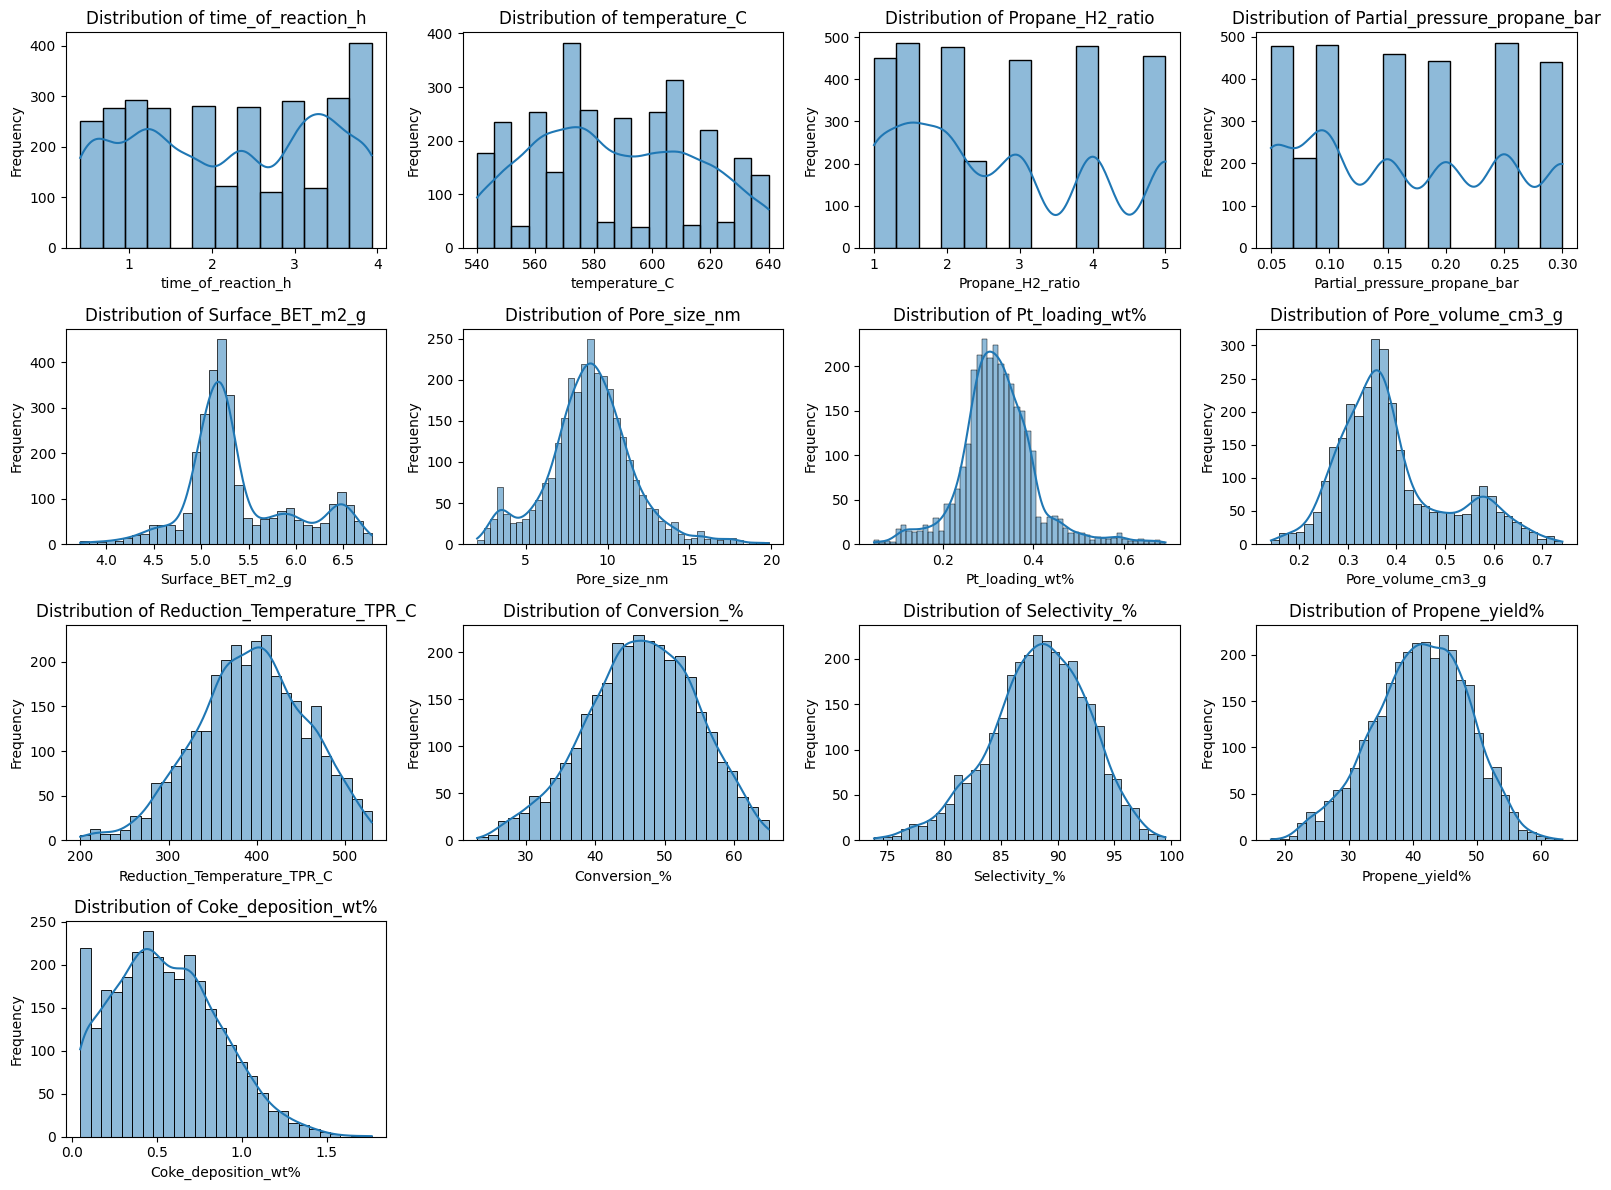

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("**1. Initial Data Inspection**\n")
print("DataFrame Information (after preprocessing):")
df_processed.info()

print("\nDescriptive Statistics (after preprocessing):")
display(df_processed.describe())

print("\n**2. Univariate Analysis (Distributions)**\n")

numerical_features = df_processed.select_dtypes(include=np.number).columns.tolist()
num_plots = len(numerical_features)
if num_plots > 0:
    n_cols = 4
    n_rows = (num_plots + n_cols - 1) // n_cols
    plt.figure(figsize=(n_cols * 4, n_rows * 3))
    for i, col in enumerate(numerical_features):
        plt.subplot(n_rows, n_cols, i + 1)
        sns.histplot(df_processed[col], kde=True)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
else:
    print("No numerical features to plot.")


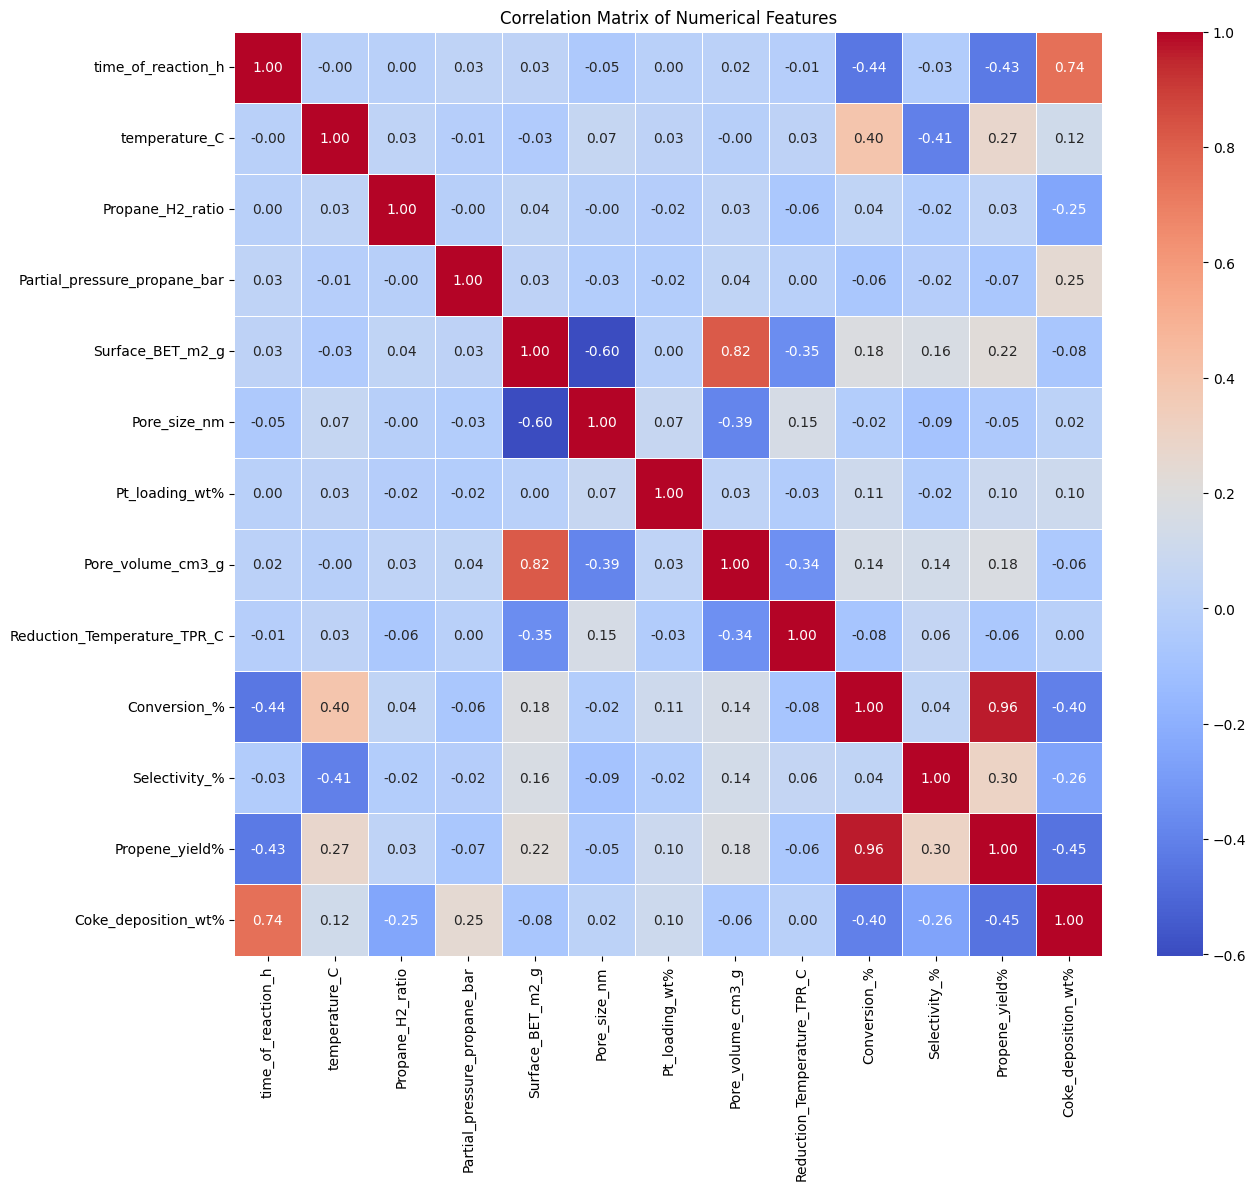

In [ ]:
# Calculate the correlation matrix
correlation_matrix = df_processed[numerical_features].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()


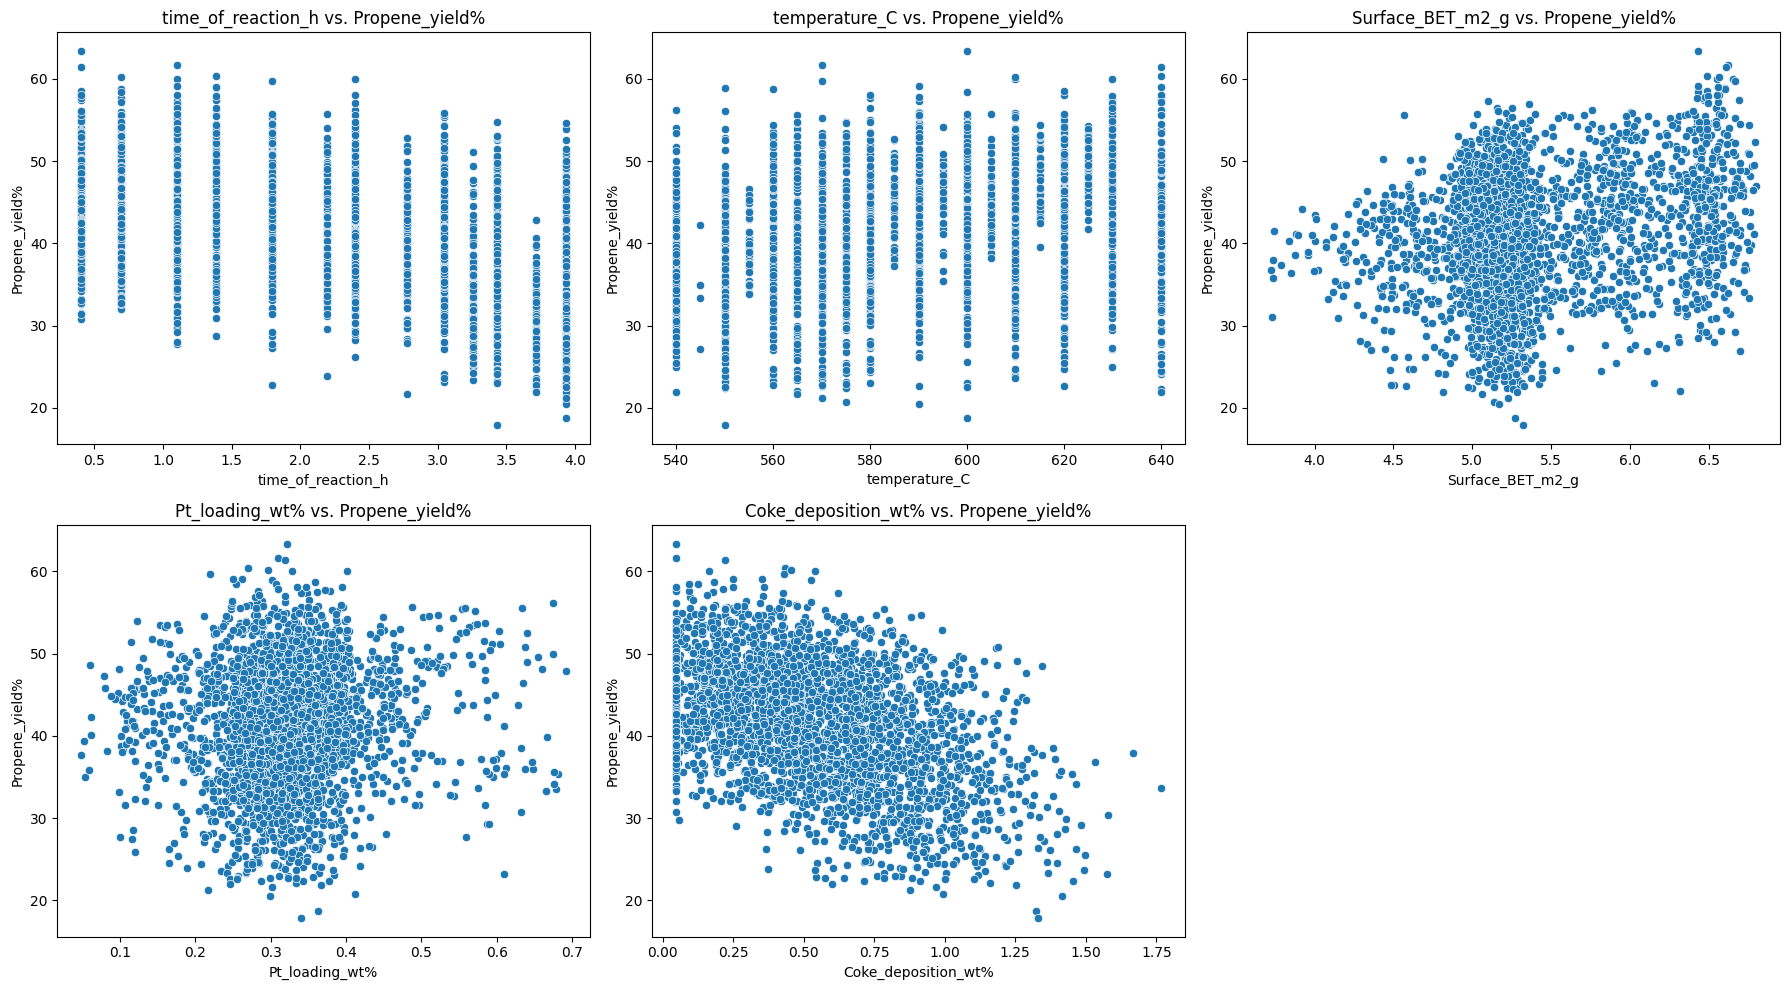

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='seaborn')

features_to_plot_vs_target = ['time_of_reaction_h', 'temperature_C', 'Surface_BET_m2_g', 'Pt_loading_wt%', 'Coke_deposition_wt%']

plt.figure(figsize=(18, 10))
for i, feature in enumerate(features_to_plot_vs_target):
    if feature in df_processed.columns and 'Propene_yield%' in df_processed.columns:
        plt.subplot(2, 3, i + 1)
        sns.scatterplot(x=df_processed[feature], y=df_processed['Propene_yield%'])
        plt.title(f'{feature} vs. Propene_yield%')
        plt.xlabel(feature)
        plt.ylabel('Propene_yield%')
    else:
        print(f"Warning: Feature '{feature}' or 'Propene_yield%' not found in DataFrame for scatter plot.")
plt.tight_layout()
plt.show()

In [ ]:
target_cols = ['Conversion_%', 'Selectivity_%', 'Propene_yield%', 'Coke_deposition_wt%']

X = df_processed.drop(columns=target_cols).copy()
y = df_processed[target_cols].copy()

print("Features (X) head:")
display(X.head())
print("\nTargets (y) head:")
display(y.head())

Features (X) head:


,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Pore_volume_cm3_g,Reduction_Temperature_TPR_C,Catalyst_Pt-Bi/Al₂O₃,...,"Dopants_Pt-M_Sn,La","Dopants_Pt-M_Sn,Li","Dopants_Pt-M_Sn,Mg","Dopants_Pt-M_Sn,Mn","Dopants_Pt-M_Sn,Na","Dopants_Pt-M_Sn,Pb","Dopants_Pt-M_Sn,Sr","Dopants_Pt-M_Sn,Zn",Dopants_Pt-M_V,Dopants_Pt-M_Zn
0,0.405465,570,5.0,0.05,5.141664,11.70,0.392042,0.379121,377,False,...,False,False,False,False,False,False,False,False,False,False
1,1.386294,600,5.0,0.10,5.122177,6.86,0.275356,0.366863,473,False,...,False,False,False,False,False,False,False,False,False,False
2,0.693147,570,1.5,0.08,4.953006,6.14,0.350657,0.347483,358,False,...,False,False,False,False,False,False,False,False,False,False
3,3.931826,630,5.0,0.25,5.183468,11.16,0.361165,0.371357,352,False,...,False,False,False,False,False,False,False,False,False,False
4,3.044522,550,1.0,0.20,5.276583,8.64,0.370874,0.282770,356,False,...,False,False,False,False,False,False,False,False,False,False



Targets (y) head:


,Conversion_%,Selectivity_%,Propene_yield%,Coke_deposition_wt%
0,46.52,89.99,41.86,0.065788
1,52.18,91.20,47.59,0.702107
2,44.35,91.68,40.66,0.345007
3,52.48,84.90,44.55,1.205372
4,43.57,91.58,39.90,1.064366


# 1.   Applying ANN Model on the dataset

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

X_scaled = x_scaler.fit_transform(X)
y_scaled = y_scaler.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

print("Data scaled and split into training and testing sets.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

Data scaled and split into training and testing sets.
X_train shape: (2400, 96)
X_test shape: (600, 96)
y_train shape: (2400, 4)
y_test shape: (600, 4)


In [ ]:
!pip install tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
num_input_features = X_train.shape[1]
num_output_targets = y_train.shape[1]

print(f"Number of input features: {num_input_features}")
print(f"Number of output targets: {num_output_targets}")

model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(num_input_features,)))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(num_output_targets, activation='linear'))
model.summary()

print("ANN model architecture defined.")

Number of input features: 96
Number of output targets: 4


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,884 (89.39 KB)

 Trainable params: 22,884 (89.39 KB)

 Non-trainable params: 0 (0.00 B)

ANN model architecture defined.


In [ ]:
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error', 'mean_squared_error'])

print("ANN model compiled successfully.")

ANN model compiled successfully.


In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("ANN model training complete.")

Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1007 - mean_absolute_error: 0.2419 - mean_squared_error: 0.1007 - val_loss: 0.0198 - val_mean_absolute_error: 0.1117 - val_mean_squared_error: 0.0198
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0176 - mean_absolute_error: 0.1035 - mean_squared_error: 0.0176 - val_loss: 0.0132 - val_mean_absolute_error: 0.0899 - val_mean_squared_error: 0.0132
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0120 - mean_absolute_error: 0.0849 - mean_squared_error: 0.0120 - val_loss: 0.0120 - val_mean_absolute_error: 0.0847 - val_mean_squared_error: 0.0120
Epoch 4/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0105 - mean_absolute_error: 0.0794 - mean_squared_error: 0.0105 - val_loss: 0.0114 - val_mean_absolute_error: 0.0817 - val_mean_squared_error: 0.0114
Epoch 5/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0095 - mean_absolute_error: 0.0755 - mean_squared_error: 0.0095 - val_loss: 0.0112 - val_mean_a

In [ ]:
loss, mae, mse = model.evaluate(X_test, y_test, verbose=0)

print(f'Test Loss: {loss:.4f}')
print(f'Test Mean Absolute Error (MAE): {mae:.4f}')
print(f'Test Mean Squared Error (MSE): {mse:.4f}')

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


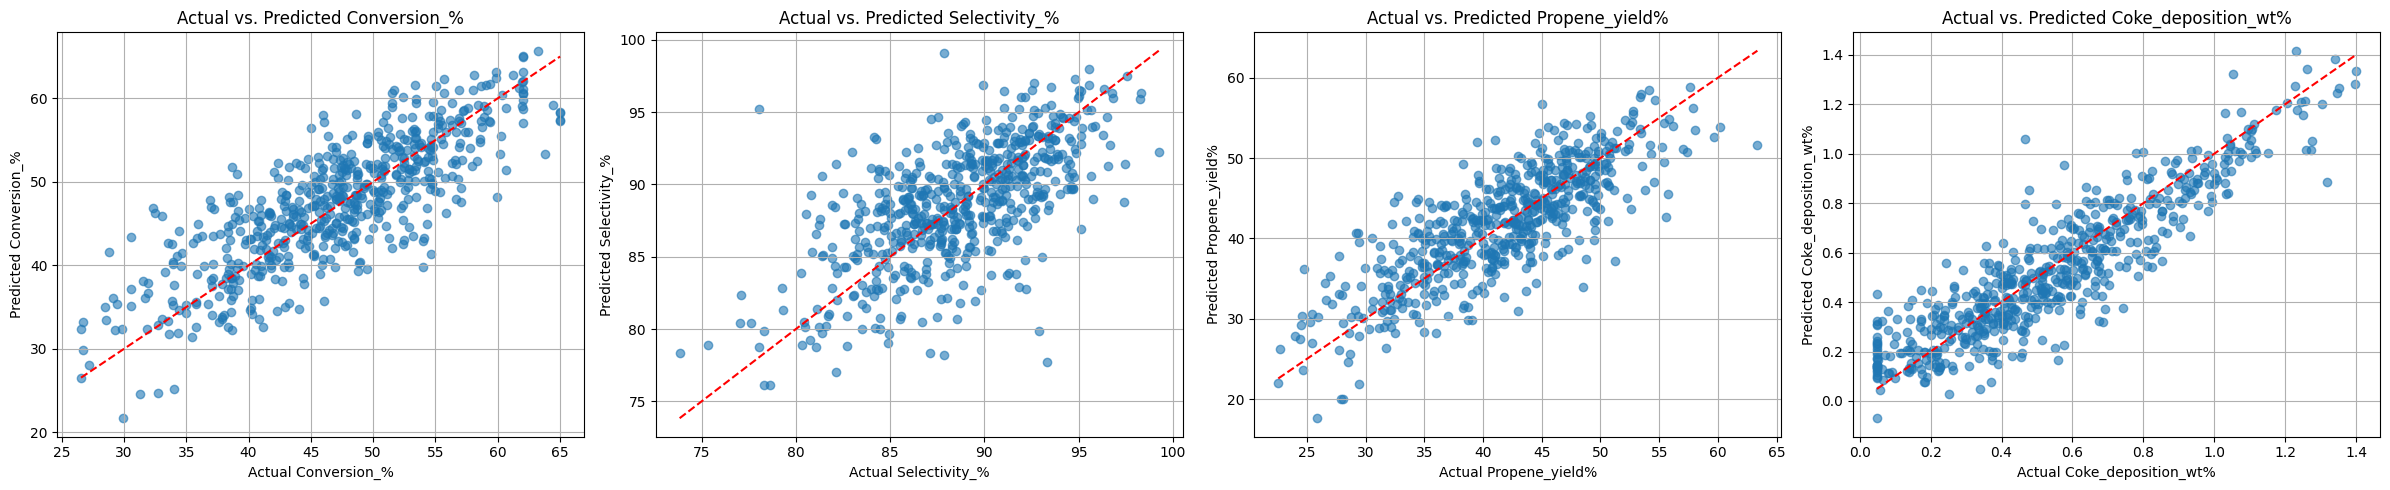

Visualizations of actual vs. predicted target values generated.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_scaled = model.predict(X_test)

y_test_inv = y_scaler.inverse_transform(y_test)
y_pred_inv = y_scaler.inverse_transform(y_pred_scaled)


target_names = y.columns

plt.figure(figsize=(24, 5))

for i, target_name in enumerate(target_names):
    plt.subplot(1, len(target_names), i + 1)
    plt.scatter(y_test_inv[:, i], y_pred_inv[:, i], alpha=0.6)
    plt.plot([min(y_test_inv[:, i]), max(y_test_inv[:, i])], [min(y_test_inv[:, i]), max(y_test_inv[:, i])], 'r--')
    plt.title(f'Actual vs. Predicted {target_name}')
    plt.xlabel(f'Actual {target_name}')
    plt.ylabel(f'Predicted {target_name}')
    plt.grid(True)

plt.tight_layout()
plt.show()

print("Visualizations of actual vs. predicted target values generated.")

In [ ]:
from sklearn.metrics import r2_score
print("R-squared Scores for Each Target Variable:")
for i, target_name in enumerate(target_names):
    r2 = r2_score(y_test_inv[:, i], y_pred_inv[:, i])
    print(f"  {target_name}: {r2:.4f}")

R-squared Scores for Each Target Variable:
  Conversion_%: 0.6268
  Selectivity_%: 0.2894
  Propene_yield%: 0.6081
  Coke_deposition_wt%: 0.8159


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
original_indices = df_processed.index
_, test_indices = train_test_split(original_indices, test_size=0.2, random_state=42)

df_test_summary = df.loc[test_indices].copy()

df_test_summary['Actual_Conversion_%'] = y_test_inv[:, 0]
df_test_summary['Actual_Selectivity_%'] = y_test_inv[:, 1]
df_test_summary['Actual_Propene_yield%'] = y_test_inv[:, 2]
df_test_summary['Actual_Coke_deposition_wt%'] = y_test_inv[:, 3]
df_test_summary['Predicted_Conversion_%'] = y_pred_inv[:, 0]
df_test_summary['Predicted_Selectivity_%'] = y_pred_inv[:, 1]
df_test_summary['Predicted_Propene_yield%'] = y_pred_inv[:, 2]
df_test_summary['Predicted_Coke_deposition_wt%'] = y_pred_inv[:, 3]

print("df_test_summary created and populated with actual and predicted target values:")
display(df_test_summary.head())

df_test_summary created and populated with actual and predicted target values:


,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Catalyst,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Dopants_Pt-M,Pore_volume_cm3_g,...,Propene_yield%,Coke_deposition_wt%,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%,Predicted_Conversion_%,Predicted_Selectivity_%,Predicted_Propene_yield%,Predicted_Coke_deposition_wt%
1801,5.0,620,3.0,0.15,Pt-Mn/Al₂O₃,197.3,9.44,0.459,Mn,0.3136,...,42.46,0.876,48.55,87.46,42.46,0.629142,47.339466,80.848068,39.345226,0.567103
1190,20.0,610,3.0,0.08,Pt/SiO₂,392.5,13.60,0.535,NaN,0.7543,...,37.29,0.594,47.79,78.02,37.29,0.466247,50.843525,78.751495,40.607960,1.057760
1817,3.0,580,5.0,0.30,Pt-Mn/Al₂O₃,148.3,10.60,0.389,Mn,0.5283,...,33.09,0.900,39.70,83.37,33.09,0.641854,42.547646,88.004585,37.300110,0.439635
251,1.0,640,1.5,0.10,Pt-Sn/SiO₂,274.1,11.21,0.344,Sn,0.5909,...,45.56,0.361,51.50,88.47,45.56,0.308220,59.456242,92.734093,53.832478,0.348151
2505,1.0,640,5.0,0.05,Pt-Zn/SBA-15,640.0,7.37,0.461,Zn,0.8120,...,57.61,0.097,63.23,91.11,57.61,0.092579,65.696472,90.320946,58.883976,0.117464


In [ ]:
grouped_performance = df_test_summary.groupby(['Catalyst', 'Dopants_Pt-M'])[['Actual_Conversion_%', 'Actual_Selectivity_%', 'Actual_Propene_yield%', 'Actual_Coke_deposition_wt%']].mean()

print("Top 5 Catalyst Combinations for Actual Conversion_%")
display(grouped_performance.sort_values(by='Actual_Conversion_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Selectivity_%")
display(grouped_performance.sort_values(by='Actual_Selectivity_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Propene_yield%")
display(grouped_performance.sort_values(by='Actual_Propene_yield%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Coke_deposition_wt% (lowest is best)")
display(grouped_performance.sort_values(by='Actual_Coke_deposition_wt%', ascending=True).head(5))

Top 5 Catalyst Combinations for Actual Conversion_%


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Zn/Al₂O₃,Zn,55.780769,88.759231,49.457692,0.479137
Pt-Zn/SiO₂,Zn,54.165000,92.471667,49.921667,0.404701
Pt-Sn/SBA-15,Sn,53.218000,91.531000,48.546000,0.488668
Pt-Sn-In/Al₂O₃,"Sn,In",52.243333,91.779167,47.850000,0.542724



Top 5 Catalyst Combinations for Actual Selectivity_%


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Ga/SiO₂,Ga,46.730000,92.617778,43.178889,0.255325
Pt-Zn/SiO₂,Zn,54.165000,92.471667,49.921667,0.404701
Pt-Sn/DMSN,Sn,50.910833,92.445000,46.970833,0.480048
Pt-Sn/SiO₂,Sn,51.060769,92.346923,47.085385,0.483130



Top 5 Catalyst Combinations for Actual Propene_yield%


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Zn/SiO₂,Zn,54.165000,92.471667,49.921667,0.404701
Pt-Zn/Al₂O₃,Zn,55.780769,88.759231,49.457692,0.479137
Pt-Sn/SBA-15,Sn,53.218000,91.531000,48.546000,0.488668
Pt-Sn-In/Al₂O₃,"Sn,In",52.243333,91.779167,47.850000,0.542724



Top 5 Catalyst Combinations for Actual Coke_deposition_wt% (lowest is best)


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Ga/SiO₂,Ga,46.730000,92.617778,43.178889,0.255325
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Ga/Al₂O₃,Ga,51.060909,89.722727,45.673636,0.304330
Pt-Sn-Ce/Al₂O₃,"Sn,Ce",51.307500,91.073333,46.633333,0.361142
Pt-Ga/SBA-15,Ga,46.426667,90.543333,42.056667,0.375671


# 2. Applying Random forest  Model on the dataset

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

print("Random Forest Regressor model initialized.")

print("Training Random Forest model...")
rf_model.fit(X_train, y_train)
print("Random Forest model training complete.")

###  Random Forest Model Evaluation

In [ ]:

y_pred_scaled_rf = rf_model.predict(X_test)

y_test_inv_rf = y_scaler.inverse_transform(y_test)
y_pred_inv_rf = y_scaler.inverse_transform(y_pred_scaled_rf)

target_names = y.columns

print("\nRandom Forest Model Evaluation:")
print("-------------------------------")

for i, target_name in enumerate(target_names):
    mae = mean_absolute_error(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])
    mse = mean_squared_error(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])
    r2 = r2_score(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])

    print(f"\nTarget: {target_name}")
    print(f"  Mean Absolute Error (MAE): {mae:.4f}")
    print(f"  Mean Squared Error (MSE): {mse:.4f}")
    print(f"  R-squared (R2): {r2:.4f}")

### Visualizing Random Forest Predictions

In [ ]:
plt.figure(figsize=(24, 5))

for i, target_name in enumerate(target_names):
    plt.subplot(1, len(target_names), i + 1)
    plt.scatter(y_test_inv_rf[:, i], y_pred_inv_rf[:, i], alpha=0.6)
    plt.plot([min(y_test_inv_rf[:, i]), max(y_test_inv_rf[:, i])], [min(y_test_inv_rf[:, i]), max(y_test_inv_rf[:, i])], 'r--')
    plt.title(f'RF: Actual vs. Predicted {target_name}')
    plt.xlabel(f'Actual {target_name}')
    plt.ylabel(f'Predicted {target_name}')
    plt.grid(True)

plt.tight_layout()
plt.show()

print("Visualizations of actual vs. predicted target values generated for Random Forest model.")

### Random Forest: Catalyst Performance Analysis

In [ ]:
_, test_indices = train_test_split(df_processed.index, test_size=0.2, random_state=42)

y_pred_scaled_rf = rf_model.predict(X_test)
y_test_inv_rf = y_scaler.inverse_transform(y_test)
y_pred_inv_rf = y_scaler.inverse_transform(y_pred_scaled_rf)

df_test_summary_rf = df.loc[test_indices].copy()

df_test_summary_rf['Actual_Conversion_%'] = y_test_inv_rf[:, 0]
df_test_summary_rf['Actual_Selectivity_%'] = y_test_inv_rf[:, 1]
df_test_summary_rf['Actual_Propene_yield%'] = y_test_inv_rf[:, 2]
df_test_summary_rf['Actual_Coke_deposition_wt%'] = y_test_inv_rf[:, 3]

df_test_summary_rf['Predicted_Conversion_%'] = y_pred_inv_rf[:, 0]
df_test_summary_rf['Predicted_Selectivity_%'] = y_pred_inv_rf[:, 1]
df_test_summary_rf['Predicted_Propene_yield%'] = y_pred_inv_rf[:, 2]
df_test_summary_rf['Predicted_Coke_deposition_wt%'] = y_pred_inv_rf[:, 3]

print("df_test_summary_rf created and populated with actual and predicted target values from Random Forest model:")
display(df_test_summary_rf.head())

In [ ]:
grouped_performance_rf = df_test_summary_rf.groupby(['Catalyst', 'Dopants_Pt-M'])[['Actual_Conversion_%', 'Actual_Selectivity_%', 'Actual_Propene_yield%', 'Actual_Coke_deposition_wt%']].mean()

print("Top 5 Catalyst Combinations for Actual Conversion_% (Random Forest)")
display(grouped_performance_rf.sort_values(by='Actual_Conversion_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Selectivity_% (Random Forest)")
display(grouped_performance_rf.sort_values(by='Actual_Selectivity_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Propene_yield% (Random Forest)")
display(grouped_performance_rf.sort_values(by='Actual_Propene_yield%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Coke_deposition_wt% (lowest is best for Random Forest)")
display(grouped_performance_rf.sort_values(by='Actual_Coke_deposition_wt%', ascending=True).head(5))

# 3. Applying CatBoost Model on the dataset

In [ ]:
!pip install catboost
import catboost as cb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cb_model = cb.CatBoostRegressor(iterations=100,
                                 learning_rate=0.1,
                                 depth=6,
                                 loss_function='MultiRMSE',
                                 random_seed=42,
                                 verbose=0,
                                 thread_count=-1)

print("CatBoost Regressor model initialized.")

# Train the model
print("Training CatBoost model...")
cb_model.fit(X_train, y_train)
print("CatBoost model training complete.")

### CatBoost Model Evaluation

In [ ]:

y_pred_scaled_cb = cb_model.predict(X_test)
y_test_inv_cb = y_scaler.inverse_transform(y_test)
y_pred_inv_cb = y_scaler.inverse_transform(y_pred_scaled_cb)
target_names = y.columns

print("\nCatBoost Model Evaluation:")
print("--------------------------")

for i, target_name in enumerate(target_names):
    mae = mean_absolute_error(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])
    mse = mean_squared_error(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])
    r2 = r2_score(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])

    print(f"\nTarget: {target_name}")
    print(f"  Mean Absolute Error (MAE): {mae:.4f}")
    print(f"  Mean Squared Error (MSE): {mse:.4f}")
    print(f"  R-squared (R2): {r2:.4f}")

### Visualizing CatBoost Predictions

In [ ]:
plt.figure(figsize=(24, 5))

for i, target_name in enumerate(target_names):
    plt.subplot(1, len(target_names), i + 1)
    plt.scatter(y_test_inv_cb[:, i], y_pred_inv_cb[:, i], alpha=0.6)
    plt.plot([min(y_test_inv_cb[:, i]), max(y_test_inv_cb[:, i])], [min(y_test_inv_cb[:, i]), max(y_test_inv_cb[:, i])], 'r--')
    plt.title(f'CatBoost: Actual vs. Predicted {target_name}')
    plt.xlabel(f'Actual {target_name}')
    plt.ylabel(f'Predicted {target_name}')
    plt.grid(True)

plt.tight_layout()
plt.show()

print("Visualizations of actual vs. predicted target values generated for CatBoost model.")

### CatBoost: Catalyst Performance Analysis

In [ ]:
# test set
_, test_indices = train_test_split(df_processed.index, test_size=0.2, random_state=42)

# summary DataFrame
df_test_summary_cb = df.loc[test_indices].copy()

df_test_summary_cb['Actual_Conversion_%'] = y_test_inv_cb[:, 0]
df_test_summary_cb['Actual_Selectivity_%'] = y_test_inv_cb[:, 1]
df_test_summary_cb['Actual_Propene_yield%'] = y_test_inv_cb[:, 2]
df_test_summary_cb['Actual_Coke_deposition_wt%'] = y_test_inv_cb[:, 3]

df_test_summary_cb['Predicted_Conversion_%'] = y_pred_inv_cb[:, 0]
df_test_summary_cb['Predicted_Selectivity_%'] = y_pred_inv_cb[:, 1]
df_test_summary_cb['Predicted_Propene_yield%'] = y_pred_inv_cb[:, 2]
df_test_summary_cb['Predicted_Coke_deposition_wt%'] = y_pred_inv_cb[:, 3]

print("df_test_summary_cb created and populated with actual and predicted target values from CatBoost model:")
display(df_test_summary_cb.head())

In [ ]:
grouped_performance_cb = df_test_summary_cb.groupby(['Catalyst', 'Dopants_Pt-M'])[['Actual_Conversion_%', 'Actual_Selectivity_%', 'Actual_Propene_yield%', 'Actual_Coke_deposition_wt%']].mean()

print("Top 5 Catalyst Combinations for Actual Conversion_% (CatBoost)")
display(grouped_performance_cb.sort_values(by='Actual_Conversion_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Selectivity_% (CatBoost)")
display(grouped_performance_cb.sort_values(by='Actual_Selectivity_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Propene_yield% (CatBoost)")
display(grouped_performance_cb.sort_values(by='Actual_Propene_yield%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Coke_deposition_wt% (lowest is best for CatBoost)")
display(grouped_performance_cb.sort_values(by='Actual_Coke_deposition_wt%', ascending=True).head(5))

# Applying XGBoost Model on the dataset

In [ ]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42, n_jobs=-1)

print("XGBoost Regressor model initialized.")

print("Training XGBoost model...")

xgb_model.fit(X_train, y_train)
print("XGBoost model training complete.")

### XGBoost Model Evaluation

In [ ]:
y_pred_scaled_xgb = xgb_model.predict(X_test)

y_test_inv_xgb = y_scaler.inverse_transform(y_test)
y_pred_inv_xgb = y_scaler.inverse_transform(y_pred_scaled_xgb)

target_names = y.columns

print("\nXGBoost Model Evaluation:")
print("-------------------------")

for i, target_name in enumerate(target_names):
    mae = mean_absolute_error(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])
    mse = mean_squared_error(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])
    r2 = r2_score(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])

    print(f"\nTarget: {target_name}")
    print(f"  Mean Absolute Error (MAE): {mae:.4f}")
    print(f"  Mean Squared Error (MSE): {mse:.4f}")
    print(f"  R-squared (R2): {r2:.4f}")

### Visualizing XGBoost Predictions

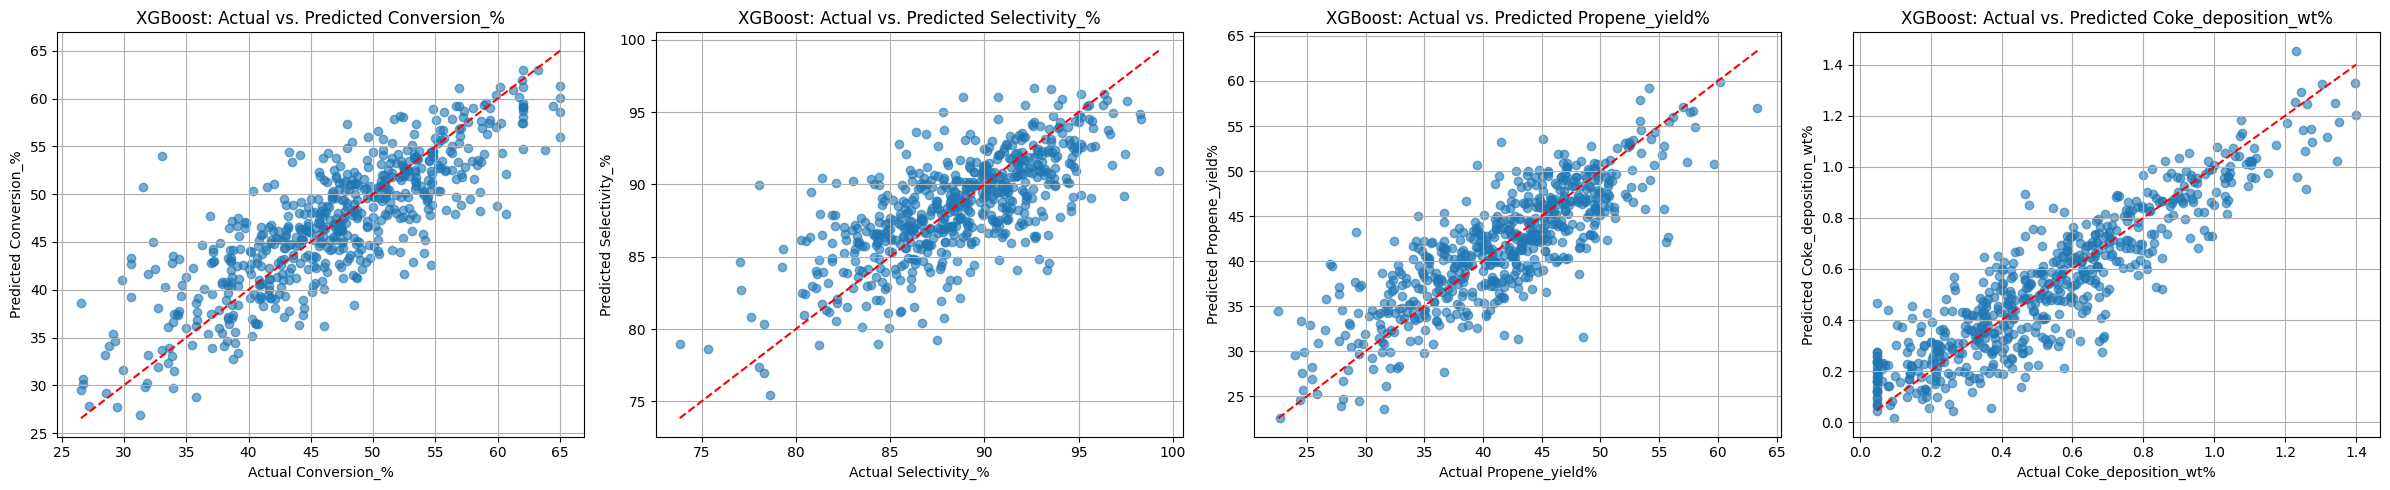

Visualizations of actual vs. predicted target values generated for XGBoost model.


In [ ]:
plt.figure(figsize=(24, 5))

for i, target_name in enumerate(target_names):
    plt.subplot(1, len(target_names), i + 1)
    plt.scatter(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i], alpha=0.6)
    plt.plot([min(y_test_inv_xgb[:, i]), max(y_test_inv_xgb[:, i])], [min(y_test_inv_xgb[:, i]), max(y_test_inv_xgb[:, i])], 'r--')
    plt.title(f'XGBoost: Actual vs. Predicted {target_name}')
    plt.xlabel(f'Actual {target_name}')
    plt.ylabel(f'Predicted {target_name}')
    plt.grid(True)

plt.tight_layout()
plt.show()

print("Visualizations of actual vs. predicted target values generated for XGBoost model.")

### XGBoost: Catalyst Performance Analysis

In [ ]:
_, test_indices = train_test_split(df_processed.index, test_size=0.2, random_state=42)

df_test_summary_xgb = df.loc[test_indices].copy()

df_test_summary_xgb['Actual_Conversion_%'] = y_test_inv_xgb[:, 0]
df_test_summary_xgb['Actual_Selectivity_%'] = y_test_inv_xgb[:, 1]
df_test_summary_xgb['Actual_Propene_yield%'] = y_test_inv_xgb[:, 2]
df_test_summary_xgb['Actual_Coke_deposition_wt%'] = y_test_inv_xgb[:, 3]

df_test_summary_xgb['Predicted_Conversion_%'] = y_pred_inv_xgb[:, 0]
df_test_summary_xgb['Predicted_Selectivity_%'] = y_pred_inv_xgb[:, 1]
df_test_summary_xgb['Predicted_Propene_yield%'] = y_pred_inv_xgb[:, 2]
df_test_summary_xgb['Predicted_Coke_deposition_wt%'] = y_pred_inv_xgb[:, 3]

print("df_test_summary_xgb created and populated with actual and predicted target values from XGBoost model:")
display(df_test_summary_xgb.head())

df_test_summary_xgb created and populated with actual and predicted target values from XGBoost model:


,time_of_reaction_h,temperature_C,Propane_H2_ratio,Partial_pressure_propane_bar,Catalyst,Surface_BET_m2_g,Pore_size_nm,Pt_loading_wt%,Dopants_Pt-M,Pore_volume_cm3_g,...,Propene_yield%,Coke_deposition_wt%,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%,Predicted_Conversion_%,Predicted_Selectivity_%,Predicted_Propene_yield%,Predicted_Coke_deposition_wt%
1801,5.0,620,3.0,0.15,Pt-Mn/Al₂O₃,197.3,9.44,0.459,Mn,0.3136,...,42.46,0.876,48.55,87.46,42.46,0.629142,50.007050,79.266479,37.597321,0.646232
1190,20.0,610,3.0,0.08,Pt/SiO₂,392.5,13.60,0.535,NaN,0.7543,...,37.29,0.594,47.79,78.02,37.29,0.466247,46.984795,77.375305,38.533230,0.893516
1817,3.0,580,5.0,0.30,Pt-Mn/Al₂O₃,148.3,10.60,0.389,Mn,0.5283,...,33.09,0.900,39.70,83.37,33.09,0.641854,46.493893,85.890686,37.304295,0.493935
251,1.0,640,1.5,0.10,Pt-Sn/SiO₂,274.1,11.21,0.344,Sn,0.5909,...,45.56,0.361,51.50,88.47,45.56,0.308220,51.795860,90.327713,50.012337,0.185726
2505,1.0,640,5.0,0.05,Pt-Zn/SBA-15,640.0,7.37,0.461,Zn,0.8120,...,57.61,0.097,63.23,91.11,57.61,0.092579,63.013695,90.134598,56.588764,0.082940


In [ ]:
grouped_performance_xgb = df_test_summary_xgb.groupby(['Catalyst', 'Dopants_Pt-M'])[['Actual_Conversion_%', 'Actual_Selectivity_%', 'Actual_Propene_yield%', 'Actual_Coke_deposition_wt%']].mean()

print("Top 5 Catalyst Combinations for Actual Conversion_% (XGBoost)")
display(grouped_performance_xgb.sort_values(by='Actual_Conversion_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Selectivity_% (XGBoost)")
display(grouped_performance_xgb.sort_values(by='Actual_Selectivity_%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Propene_yield% (XGBoost)")
display(grouped_performance_xgb.sort_values(by='Actual_Propene_yield%', ascending=False).head(5))

print("\nTop 5 Catalyst Combinations for Actual Coke_deposition_wt% (lowest is best for XGBoost)")
display(grouped_performance_xgb.sort_values(by='Actual_Coke_deposition_wt%', ascending=True).head(5))

Top 5 Catalyst Combinations for Actual Conversion_% (XGBoost)


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Zn/Al₂O₃,Zn,55.780769,88.759231,49.457692,0.479137
Pt-Zn/SiO₂,Zn,54.165000,92.471667,49.921667,0.404701
Pt-Sn/SBA-15,Sn,53.218000,91.531000,48.546000,0.488668
Pt-Sn-In/Al₂O₃,"Sn,In",52.243333,91.779167,47.850000,0.542724



Top 5 Catalyst Combinations for Actual Selectivity_% (XGBoost)


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Ga/SiO₂,Ga,46.730000,92.617778,43.178889,0.255325
Pt-Zn/SiO₂,Zn,54.165000,92.471667,49.921667,0.404701
Pt-Sn/DMSN,Sn,50.910833,92.445000,46.970833,0.480048
Pt-Sn/SiO₂,Sn,51.060769,92.346923,47.085385,0.483130



Top 5 Catalyst Combinations for Actual Propene_yield% (XGBoost)


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Zn/SiO₂,Zn,54.165000,92.471667,49.921667,0.404701
Pt-Zn/Al₂O₃,Zn,55.780769,88.759231,49.457692,0.479137
Pt-Sn/SBA-15,Sn,53.218000,91.531000,48.546000,0.488668
Pt-Sn-In/Al₂O₃,"Sn,In",52.243333,91.779167,47.850000,0.542724



Top 5 Catalyst Combinations for Actual Coke_deposition_wt% (lowest is best for XGBoost)


,,Actual_Conversion_%,Actual_Selectivity_%,Actual_Propene_yield%,Actual_Coke_deposition_wt%
Catalyst,Dopants_Pt-M,,,,
Pt-Ga/SiO₂,Ga,46.730000,92.617778,43.178889,0.255325
Pt-Zn/SBA-15,Zn,59.105455,93.212727,55.054545,0.284299
Pt-Ga/Al₂O₃,Ga,51.060909,89.722727,45.673636,0.304330
Pt-Sn-Ce/Al₂O₃,"Sn,Ce",51.307500,91.073333,46.633333,0.361142
Pt-Ga/SBA-15,Ga,46.426667,90.543333,42.056667,0.375671


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

r_squared_data = {
    'Target': target_variables,
    'ANN': [ann_r2[t] for t in target_variables],
    'Random Forest': [rf_r2[t] for t in target_variables],
    'XGBoost': [xgb_r2[t] for t in target_variables],
    'CatBoost': [cat_r2[t] for t in target_variables],


}
results_df = pd.DataFrame(r_squared_data)

results_df_melted = results_df.melt(id_vars=['Target'], var_name='Model', value_name='Score')

plt.figure(figsize=(12, 8))
sns.barplot(x='Target', y='Score', hue='Model', data=results_df_melted, palette='viridis')

plt.title('Model Performance Comparison (R2 Score)', fontsize=16)
plt.ylabel('R-squared Score', fontsize=12)
plt.xlabel('Target Variable', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

NameError: name 'target_variables' is not defined

### SHAP Analysis



In [ ]:

!pip install shap

import shap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("SHAP library imported successfully.")

In [ ]:

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

print(f"Shape of SHAP values: {shap_values.shape}")
print("SHAP values calculated successfully.")

#### SHAP Summary Plots


In [ ]:
target_names = y.columns

for i, target_name in enumerate(target_names):
    print(f"\nSHAP Summary Plot for {target_name}:")
    shap.summary_plot(shap_values[:, :, i], X_test, feature_names=X.columns, show=False)
    plt.title(f'SHAP Summary for {target_name}')
    plt.tight_layout()
    plt.show()

# 5. Applying Physics based LLM Model on the dataset

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import catboost as cb
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from scipy.integrate import odeint
import warnings, os, json, requests
warnings.filterwarnings("ignore")

In [ ]:
R_GAS    = 8.314      # J/(mol·K)
DH_PDH   = 124_000    # J/mol  (endothermic, van't Hoff)
DS_PDH   = 126.0      # J/(mol·K)
EA_PDH   = 90_000     # J/mol  (Arrhenius, Li et al. 2011)
EA_COKE  = 80_000     # J/mol  (Bai et al. 2003)
EA_DEACT = 70_000     # J/mol  (Fogler Ch.10)
A_PDH    = 1e7
A_COKE   = 1e5
K0       = {'C3H8': 0.5, 'C3H6': 2.0, 'H2': 0.3}     # bar⁻¹
DH_ADS   = {'C3H8': -40000, 'C3H6': -60000, 'H2': -30000}  # J/mol


In [ ]:
def k_arr(A, Ea, T_K):
    """Arrhenius rate constant k = A·exp(−Ea/RT)"""
    return A * np.exp(-Ea / (R_GAS * np.clip(T_K, 500, 1500)))

def K_ads(sp, T_K):
    """Langmuir adsorption constant"""
    return K0[sp] * np.exp(-DH_ADS[sp] / (R_GAS * T_K))

def keq(T_K):
    """van't Hoff equilibrium constant  C3H8 ⇌ C3H6 + H2"""
    return np.exp(-DH_PDH / (R_GAS * T_K) + DS_PDH / R_GAS)

def x_eq(T_K):
    """Equilibrium conversion from  Kp = X²P/(1−X)  at P=1 bar"""
    K = keq(T_K)
    return np.clip((-K + np.sqrt(K**2 + 4*K)) / 2, 0.0, 0.999)

def r_lh(T_K, P_C3H8, P_C3H6=0.0, P_H2=0.0):
    """Langmuir-Hinshelwood rate [mol/(g_cat·s)] — RDS = 1st C-H cleavage"""
    k   = k_arr(A_PDH, EA_PDH, T_K)
    KC8 = K_ads('C3H8', T_K)
    KC6 = K_ads('C3H6', T_K)
    KH2 = K_ads('H2',   T_K)
    denom = (1 + KC8*P_C3H8 + KC6*P_C3H6 + KH2*P_H2) ** 2
    return k * KC8 * P_C3H8 / denom

def fogler_activity(t_h, T_K, C_coke, k_d0=0.05, alpha=0.8):
    """Fogler deactivation a(t) = exp(−kd·Cc^α·t)"""
    kd = k_arr(k_d0, EA_DEACT, T_K)
    return np.exp(-kd * (np.clip(C_coke, 0.01, 10.0)**alpha) * t_h)

In [ ]:
def inject_physics_features(df_in):
    """
    Add 9 physics-derived columns to the dataframe.
    These follow AFTER log1p + MinMax in your pipeline.
    """
    T_K = df_in['temperature_C'].values + 273.15
    P   = df_in['Partial_pressure_propane_bar'].values
    t   = df_in['time_of_reaction_h'].values
    Cc  = df_in['Coke_deposition_wt%'].values.clip(0.05)
    BET = df_in['Surface_BET_m2_g'].values
    Pt  = df_in['Pt_loading_wt%'].values
    pore= df_in['Pore_size_nm'].values
    H2r = df_in['Propane_H2_ratio'].values

    out = df_in.copy()
    # Law 3: van't Hoff equilibrium
    out['phys_Keq']       = np.log1p(keq(T_K))
    out['phys_Xeq_pct']   = x_eq(T_K) * 100
    # Law 2: Arrhenius
    out['phys_lnk_PDH']   = np.log(k_arr(A_PDH, EA_PDH, T_K) + 1e-100)
    out['phys_lnk_coke']  = np.log(k_arr(A_COKE, EA_COKE, T_K) + 1e-100)
    # Law 4: Gibbs free energy
    out['phys_deltaG']    = (DH_PDH - T_K * DS_PDH) / 1000
    # Law 1: Langmuir-Hinshelwood rate
    out['phys_r_LH']      = r_lh(T_K, P.clip(1e-4)) * 1000
    # Law 6: Fogler deactivation
    out['phys_activity']  = fogler_activity(t, T_K, Cc)
    # Law 9: H₂ inhibition of coke
    out['phys_H2_inhib']  = 1.0 / (1.0 + H2r * 0.1)
    # Surface chemistry (BET active site density)
    out['phys_act_sites'] = BET * Pt / 100
    return out

In [ ]:
class PhysicsANN(nn.Module):
    """
    Same architecture as your notebook Sequential model.
    Dense(128,relu) → Dense(64,relu) → Dense(32,relu) → Dense(4,linear)
    """
    def __init__(self, in_dim, out_dim=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(),
            nn.Linear(128, 64),    nn.ReLU(),
            nn.Linear(64, 32),     nn.ReLU(),
            nn.Linear(32, out_dim)
        )

    def forward(self, x):
        return self.net(x)

def physics_loss(pred, target, Xeq_batch, yield_batch,
                 lam_data=1.0, lam_eq=0.5, lam_yield=0.4, lam_pos=0.1):
    """
    L_total = lam_data * MSE(pred, target)
            + lam_eq   * mean(max(0, X_pred - X_eq))²   ← equilibrium ceiling
            + lam_yield* ||Y_pred - X_pred*S_pred/100||² ← stoichiometry
            + lam_pos  * mean(max(0, -pred))²            ← non-negativity
    """
    mse = nn.functional.mse_loss
    X_p = pred[:, 0];  S_p = pred[:, 1];  Y_p = pred[:, 2]

    L_data  = mse(pred, target)
    L_eq    = torch.mean(torch.clamp(X_p - Xeq_batch, min=0) ** 2)
    Y_calc  = X_p * S_p / 100.0
    L_yield = mse(Y_calc, yield_batch)
    L_pos   = torch.mean(torch.clamp(-pred, min=0) ** 2)

    total = (lam_data * L_data + lam_eq * L_eq +
             lam_yield * L_yield + lam_pos * L_pos)
    return total, {'data': L_data.item(), 'eq': L_eq.item(),
                   'yield': L_yield.item(), 'pos': L_pos.item()}

def train_physics_ann(X_tr, y_tr, Xeq_tr, yield_tr,
                      X_vl, y_vl, Xeq_vl, Yld_vl, # Added Xeq_vl, Yld_vl to signature
                      in_dim, n_epochs=100, lr=1e-3, batch=32):
    """Train physics-informed ANN — mirrors your model.fit(epochs=100, batch=32)"""
    model = PhysicsANN(in_dim)
    opt   = optim.Adam(model.parameters(), lr=lr)
    sched = optim.lr_scheduler.StepLR(opt, step_size=40, gamma=0.5)

    Xtr_t = torch.tensor(X_tr, dtype=torch.float32)
    ytr_t = torch.tensor(y_tr, dtype=torch.float32)
    Xvl_t = torch.tensor(X_vl, dtype=torch.float32)
    yvl_t = torch.tensor(y_vl, dtype=torch.float32)
    Xeq_t = Xeq_tr.clone()
    Yld_t = yield_tr.clone()

    ds    = TensorDataset(Xtr_t, ytr_t, Xeq_t, Yld_t)
    dl    = DataLoader(ds, batch_size=batch, shuffle=True)

    best_val = float('inf')
    train_hist, val_hist = [], []

    for ep in range(n_epochs):
        model.train(); ep_loss = 0.0
        for Xb, yb, Xeq_b, Yld_b in dl:
            pred = model(Xb)
            loss, _ = physics_loss(pred, yb, Xeq_b, Yld_b)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); ep_loss += loss.item()
        sched.step()

        model.eval()
        with torch.no_grad():
            val_pred = model(Xvl_t)
            vl_total, _ = physics_loss(val_pred, yvl_t, Xeq_vl, Yld_vl)
            vl = vl_total.item()

        tl = ep_loss / len(dl)
        train_hist.append(tl); val_hist.append(vl)
        if vl < best_val:
            best_val = vl
            torch.save(model.state_dict(), '/content/best_pi_ann.pt')
        if (ep + 1) % 20 == 0:
            print(f"   Epoch [{ep+1:3d}/{n_epochs}]  train={tl:.4f}  val={vl:.4f}")

    model.load_state_dict(torch.load('/content/best_pi_ann.pt', map_location='cpu'))
    return model, train_hist, val_hist

In [ ]:
num_input  = X_train.shape[1]
num_output = y_train.shape[1]

TARGET_COLS = target_cols if 'target_cols' in locals() else ['Conversion_%', 'Selectivity_%', 'Propene_yield%', 'Coke_deposition_wt%']

# LLM Domain Prior heuristic cache for catalyst selectivity modifiers based on promoter chemistry
llm_cache = {
    'Pt-Sn/Al2O3': {'selectivity_modifier': 1.05},
    'Pt-In/Al2O3': {'selectivity_modifier': 1.03},
    'Pt-Ga/Al2O3': {'selectivity_modifier': 1.02},
}

# --- Prepare Sub-Split for Physics-Informed Training ---
print("\n[PI-ANN] Training Physics-Informed ANN (128-64-32-4 arch, 100 epochs)...")
train_indices, _ = train_test_split(df_processed.index, test_size=0.2, random_state=42)
tr_sub_idx, vl_sub_idx = train_test_split(train_indices, test_size=0.2, random_state=42)

X_ann_tr, X_ann_vl, y_ann_tr, y_ann_vl = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42)

# Compute thermodynamic equilibrium ceiling (Xeq) and yield targets for physics loss
T_K_tr = df.loc[tr_sub_idx, 'temperature_C'].values + 273.15
Xeq_raw_tr = x_eq(T_K_tr) * 100
conv_min, conv_max = y_scaler.data_min_[0], y_scaler.data_max_[0]
Xeq_scaled_tr = (Xeq_raw_tr - conv_min) / (conv_max - conv_min + 1e-8)
Xeq_ann_tr = torch.tensor(Xeq_scaled_tr, dtype=torch.float32)
Yld_ann_tr = torch.tensor(y_ann_tr[:, 2], dtype=torch.float32)

T_K_vl = df.loc[vl_sub_idx, 'temperature_C'].values + 273.15
Xeq_raw_vl = x_eq(T_K_vl) * 100
Xeq_scaled_vl = (Xeq_raw_vl - conv_min) / (conv_max - conv_min + 1e-8)
Xeq_ann_vl = torch.tensor(Xeq_scaled_vl, dtype=torch.float32)
Yld_ann_vl = torch.tensor(y_ann_vl[:, 2], dtype=torch.float32)

pi_ann, train_hist, val_hist = train_physics_ann(
    X_ann_tr, y_ann_tr, Xeq_ann_tr, Yld_ann_tr,
    X_ann_vl, y_ann_vl, Xeq_ann_vl, Yld_ann_vl,
    in_dim=num_input, n_epochs=100, lr=1e-3, batch=32
)

pi_ann.eval()
with torch.no_grad():
    y_pred_scaled_ann = pi_ann(torch.tensor(X_test, dtype=torch.float32)).numpy()
y_pred_inv_ann = y_scaler.inverse_transform(y_pred_scaled_ann)

_, test_indices = train_test_split(df_processed.index, test_size=0.2, random_state=42)
test_cat_names = df.loc[test_indices]['Catalyst'].values if 'Catalyst' in df.columns else [None]*len(test_indices)
for i, cat in enumerate(test_cat_names):
    if cat in llm_cache:
        y_pred_inv_ann[i, 1] *= llm_cache[cat]['selectivity_modifier']
        y_pred_inv_ann[i, 1]  = np.clip(y_pred_inv_ann[i, 1], 0, 99.5)

# Enforce thermodynamic ceiling on conversion
Xeq_test_raw = x_eq(df.loc[test_indices]['temperature_C'].values + 273.15) * 100
y_pred_inv_ann[:, 0] = np.clip(y_pred_inv_ann[:, 0], 0,
                               Xeq_test_raw + 5)  # 5% tolerance

print("\n[PI-ANN] R2 on test set:")
for i, name in enumerate(TARGET_COLS):
    r2 = r2_score(y_test_inv[:, i], y_pred_inv_ann[:, i])
    print(f"   {name:28s}: {r2:.4f}")



In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd

print("-- Model Performance Summary and Comparison --")

target_variables = y.columns.tolist()

# --- Collect ANN (Standard Keras) metrics ---
ann_r2 = {}
ann_mae = {}
ann_mse = {}
for i, target_name in enumerate(target_variables):
    ann_r2[target_name] = r2_score(y_test_inv[:, i], y_pred_inv[:, i])
    ann_mae[target_name] = mean_absolute_error(y_test_inv[:, i], y_pred_inv[:, i])
    ann_mse[target_name] = mean_squared_error(y_test_inv[:, i], y_pred_inv[:, i])

# --- Collect Random Forest metrics ---
rf_r2 = {}
rf_mae = {}
rf_mse = {}
for i, target_name in enumerate(target_variables):
    rf_r2[target_name] = r2_score(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])
    rf_mae[target_name] = mean_absolute_error(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])
    rf_mse[target_name] = mean_squared_error(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])

# --- Collect XGBoost metrics ---
xgb_r2 = {}
xgb_mae = {}
xgb_mse = {}
for i, target_name in enumerate(target_variables):
    xgb_r2[target_name] = r2_score(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])
    xgb_mae[target_name] = mean_absolute_error(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])
    xgb_mse[target_name] = mean_squared_error(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])

# --- Collect CatBoost metrics ---
cat_r2 = {}
cat_mae = {}
cat_mse = {}
for i, target_name in enumerate(target_variables):
    cat_r2[target_name] = r2_score(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])
    cat_mae[target_name] = mean_absolute_error(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])
    cat_mse[target_name] = mean_squared_error(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])

# --- Collect Physics-Informed ANN metrics ---
pi_ann_r2 = {}
pi_ann_mae = {}
pi_ann_mse = {}
for i, target_name in enumerate(target_variables):
    # y_test_inv is the same for all models
    pi_ann_r2[target_name] = r2_score(y_test_inv[:, i], y_pred_inv_ann[:, i])
    pi_ann_mae[target_name] = mean_absolute_error(y_test_inv[:, i], y_pred_inv_ann[:, i])
    pi_ann_mse[target_name] = mean_squared_error(y_test_inv[:, i], y_pred_inv_ann[:, i])


# --- Print all R-squared Scores ---
print("\n--- R-squared Scores ---")
for target_name in target_variables:
    print(f"  {target_name}:")
    print(f"    ANN:         {ann_r2[target_name]:.4f}")
    print(f"    RF:          {rf_r2[target_name]:.4f}")
    print(f"    XGBoost:     {xgb_r2[target_name]:.4f}")
    print(f"    CatBoost:    {cat_r2[target_name]:.4f}")
    print(f"    PI-ANN:      {pi_ann_r2[target_name]:.4f}")

# --- Print all MAE Scores ---
print("\n--- Mean Absolute Error (MAE) Scores ---")
for target_name in target_variables:
    print(f"  {target_name}:")
    print(f"    ANN:         {ann_mae[target_name]:.4f}")
    print(f"    RF:          {rf_mae[target_name]:.4f}")
    print(f"    XGBoost:     {xgb_mae[target_name]:.4f}")
    print(f"    CatBoost:    {cat_mae[target_name]:.4f}")
    print(f"    PI-ANN:      {pi_ann_mae[target_name]:.4f}")

# --- Print all MSE Scores ---
print("\n--- Mean Squared Error (MSE) Scores ---")
for target_name in target_variables:
    print(f"  {target_name}:")
    print(f"    ANN:         {ann_mse[target_name]:.4f}")
    print(f"    RF:          {rf_mse[target_name]:.4f}")
    print(f"    XGBoost:     {xgb_mse[target_name]:.4f}")
    print(f"    CatBoost:    {cat_mse[target_name]:.4f}")
    print(f"    PI-ANN:      {pi_ann_mse[target_name]:.4f}")


# --- Consolidated Comparison DataFrame ---
results_data = []
for target_name in target_variables:
    results_data.append({'Metric': 'R2', 'Target': target_name,
                         'ANN': ann_r2[target_name], 'Random Forest': rf_r2[target_name],
                         'XGBoost': xgb_r2[target_name], 'CatBoost': cat_r2[target_name],
                         'PI-ANN': pi_ann_r2[target_name]})
    results_data.append({'Metric': 'MAE', 'Target': target_name,
                         'ANN': ann_mae[target_name], 'Random Forest': rf_mae[target_name],
                         'XGBoost': xgb_mae[target_name], 'CatBoost': cat_mae[target_name],
                         'PI-ANN': pi_ann_mae[target_name]})
    results_data.append({'Metric': 'MSE', 'Target': target_name,
                         'ANN': ann_mse[target_name], 'Random Forest': rf_mse[target_name],
                         'XGBoost': xgb_mse[target_name], 'CatBoost': cat_mse[target_name],
                         'PI-ANN': pi_ann_mse[target_name]})

comparison_df = pd.DataFrame(results_data)
display(comparison_df)

# Identify best models per target and metric
print("\n--- Best Performing Models ---")
for target_name in target_variables:
    print(f"\nTarget: {target_name}")
    target_results = comparison_df[comparison_df['Target'] == target_name]

    # R2 - higher is better
    r2_row = target_results[target_results['Metric'] == 'R2'].drop(columns=['Metric', 'Target'])
    best_r2_model = r2_row.idxmax(axis=1).iloc[0]
    best_r2_score = r2_row.max(axis=1).iloc[0]
    print(f"  Best R2: {best_r2_model} ({best_r2_score:.4f})")

    # MAE - lower is better
    mae_row = target_results[target_results['Metric'] == 'MAE'].drop(columns=['Metric', 'Target'])
    best_mae_model = mae_row.idxmin(axis=1).iloc[0]
    best_mae_score = mae_row.min(axis=1).iloc[0]
    print(f"  Best MAE: {best_mae_model} ({best_mae_score:.4f})")

    # MSE - lower is better
    mse_row = target_results[target_results['Metric'] == 'MSE'].drop(columns=['Metric', 'Target'])
    best_mse_model = mse_row.idxmin(axis=1).iloc[0]
    best_mse_score = mse_row.min(axis=1).iloc[0]
    print(f"  Best MSE: {best_mse_model} ({best_mse_score:.4f})")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

comparison_data = []

for i, target_name in enumerate(target_variables):
    # ANN Metrics
    mae_ann = mean_absolute_error(y_test_inv[:, i], y_pred_inv[:, i])
    mse_ann = mean_squared_error(y_test_inv[:, i], y_pred_inv[:, i])
    r2_ann = ann_r2[target_name]

    # Random Forest Metrics
    mae_rf = mean_absolute_error(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])
    mse_rf = mean_squared_error(y_test_inv_rf[:, i], y_pred_inv_rf[:, i])
    r2_rf = rf_r2[target_name]

    # XGBoost Metrics
    mae_xgb = mean_absolute_error(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])
    mse_xgb = mean_squared_error(y_test_inv_xgb[:, i], y_pred_inv_xgb[:, i])
    r2_xgb = xgb_r2[target_name]

    # CatBoost Metrics
    mae_cat = mean_absolute_error(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])
    mse_cat = mean_squared_error(y_test_inv_cb[:, i], y_pred_inv_cb[:, i])
    r2_cat = cat_r2[target_name]

    comparison_data.append({
        'Target Variable': target_name,
        'Metric': 'MAE',
        'ANN': f'{mae_ann:.4f}',
        'Random Forest': f'{mae_rf:.4f}',
        'XGBoost': f'{mae_xgb:.4f}',
        'CatBoost': f'{mae_cat:.4f}'
    })
    comparison_data.append({
        'Target Variable': target_name,
        'Metric': 'MSE',
        'ANN': f'{mse_ann:.4f}',
        'Random Forest': f'{mse_rf:.4f}',
        'XGBoost': f'{mse_xgb:.4f}',
        'CatBoost': f'{mse_cat:.4f}'
    })
    comparison_data.append({
        'Target Variable': target_name,
        'Metric': 'R-squared',
        'ANN': f'{r2_ann:.4f}',
        'Random Forest': f'{r2_rf:.4f}',
        'XGBoost': f'{r2_xgb:.4f}',
        'CatBoost': f'{r2_cat:.4f}'
    })

comparison_df = pd.DataFrame(comparison_data)

print("\n--- Consolidated Model Performance Comparison Matrix ---")
display(comparison_df)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

model_for_importance = xgb_model

feature_importances = model_for_importance.feature_importances_

feature_names = X.columns

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})


importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(20), palette='magma')
plt.title('Top 20 Feature Importances (XGBoost Multi-Output Model)', fontsize=16)
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

print("Top 20 Feature Importances from XGBoost Multi-Output Model:")
display(importance_df.head(20))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

metrics = ['Actual_Conversion_%', 'Actual_Selectivity_%', 'Actual_Propene_yield%', 'Actual_Coke_deposition_wt%']
titles = ['Conversion (%)', 'Selectivity (%)', 'Propene Yield (%)', 'Coke Deposition (wt%)']

plt.figure(figsize=(24, 12))

for i, metric in enumerate(metrics):
    plt.subplot(2, 4, i + 1)
    top_combinations = grouped_performance.sort_values(by=metric, ascending=False).head(5)

    if metric == 'Actual_Coke_deposition_wt%':
        top_combinations = grouped_performance.sort_values(by=metric, ascending=True).head(5)
        sns.barplot(x=top_combinations.index.map(lambda x: f'{x[0]} with {x[1]}'), y=metric, data=top_combinations, palette='magma_r')
        plt.title(f'Top 5 Catalyst for Lowest {titles[i]}')
    else:
        sns.barplot(x=top_combinations.index.map(lambda x: f'{x[0]} with {x[1]}'), y=metric, data=top_combinations, palette='viridis')
        plt.title(f'Top 5 Catalyst for Highest {titles[i]}')
    plt.xlabel('Catalyst & Dopant Combination')
    plt.ylabel(f'Average {titles[i]}')
    plt.xticks(rotation=45, ha='right')

for i, metric in enumerate(metrics):
    plt.subplot(2, 4, i + 5)
    bottom_combinations = grouped_performance.sort_values(by=metric, ascending=False).head(5)

    if metric == 'Actual_Coke_deposition_wt%':
        bottom_combinations = grouped_performance.sort_values(by=metric, ascending=False).head(5) # Highest is worst
        sns.barplot(x=bottom_combinations.index.map(lambda x: f'{x[0]} with {x[1]}'), y=metric, data=bottom_combinations, palette='viridis_r')
        plt.title(f'Bottom 5 Catalyst for Highest {titles[i]}')
    else:
        bottom_combinations = grouped_performance.sort_values(by=metric, ascending=True).head(5) # Lowest is worst
        sns.barplot(x=bottom_combinations.index.map(lambda x: f'{x[0]} with {x[1]}'), y=metric, data=bottom_combinations, palette='magma_r')
        plt.title(f'Bottom 5 Catalyst for Lowest {titles[i]}')
    plt.xlabel('Catalyst & Dopant Combination')
    plt.ylabel(f'Average {titles[i]}')
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

print("Visualizations of top and bottom catalyst and dopant combinations for all target variables generated.")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

_, test_indices_full = train_test_split(df_processed.index, test_size=0.2, random_state=42)
random_test_index_pos = np.random.randint(0, len(test_indices_full))
selected_original_index = test_indices_full[random_test_index_pos]

selected_X_test_scaled = X_test[random_test_index_pos:random_test_index_pos+1]
selected_y_test_scaled = y_test[random_test_index_pos:random_test_index_pos+1]

original_numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
original_categorical_cols_df = df.select_dtypes(include='object').columns.tolist()

all_original_input_features_names = [col for col in original_numerical_cols + original_categorical_cols_df if col not in target_cols]

original_input_features = df.loc[selected_original_index, all_original_input_features_names].to_frame().T
original_actual_targets = y_scaler.inverse_transform(selected_y_test_scaled)
original_actual_targets_df = pd.DataFrame(original_actual_targets, columns=target_cols)

print(f"--- Analyzing Example (Original Index: {selected_original_index}) ---")
print("\nOriginal Input Features for Prediction:")
display(original_input_features)
print("\nOriginal Actual Target Values:")
display(original_actual_targets_df)

# ANN Prediction
ann_pred_scaled = model.predict(selected_X_test_scaled)
ann_pred_inv = y_scaler.inverse_transform(ann_pred_scaled)
ann_pred_df = pd.DataFrame(ann_pred_inv, columns=target_cols)

# Random Forest Prediction
rf_pred_scaled = rf_model.predict(selected_X_test_scaled)
rf_pred_inv = y_scaler.inverse_transform(rf_pred_scaled)
rf_pred_df = pd.DataFrame(rf_pred_inv, columns=target_cols)

# XGBoost Prediction
xgb_pred_scaled = xgb_model.predict(selected_X_test_scaled)
xgb_pred_inv = y_scaler.inverse_transform(xgb_pred_scaled)
xgb_pred_df = pd.DataFrame(xgb_pred_inv, columns=target_cols)

# CatBoost Prediction
cb_pred_scaled = cb_model.predict(selected_X_test_scaled)
cb_pred_inv = y_scaler.inverse_transform(cb_pred_scaled)
cb_pred_df = pd.DataFrame(cb_pred_inv, columns=target_cols)

results_summary = pd.DataFrame({
    'Actual': original_actual_targets_df.iloc[0],
    'ANN_Predicted': ann_pred_df.iloc[0],
    'RF_Predicted': rf_pred_df.iloc[0],
    'XGB_Predicted': xgb_pred_df.iloc[0],
    'CB_Predicted': cb_pred_df.iloc[0]
})

results_summary['ANN_Error'] = np.abs(results_summary['Actual'] - results_summary['ANN_Predicted'])
results_summary['RF_Error'] = np.abs(results_summary['Actual'] - results_summary['RF_Predicted'])
results_summary['XGB_Error'] = np.abs(results_summary['Actual'] - results_summary['XGB_Predicted'])
results_summary['CB_Error'] = np.abs(results_summary['Actual'] - results_summary['CB_Predicted'])

print("\nDetailed Prediction and Error Analysis for Selected Example:")
display(results_summary.style.format('{:.4f}'))

sum_errors = {
    'ANN': results_summary['ANN_Error'].sum(),
    'Random Forest': results_summary['RF_Error'].sum(),
    'XGBoost': results_summary['XGB_Error'].sum(),
    'CatBoost': results_summary['CB_Error'].sum()
}


In [ ]:
def calculate_deactivation_using_baseline(model, sample_X_scaled, original_index, final_time_guess, original_df, X_cols, y_cols, x_scaler, y_scaler, is_torch=False):
    initial_time_of_reaction_h = original_df.loc[original_index, 'time_of_reaction_h']

    sample_X_df = pd.DataFrame(sample_X_scaled, columns=X_cols)

    sample_X_for_prediction = sample_X_df.copy()
    time_reaction_col_idx = X_cols.get_loc('time_of_reaction_h')
    if 'time_of_reaction_h' in highly_skewed_to_transform:
        sample_X_for_prediction.iloc[0, time_reaction_col_idx] = np.log1p(final_time_guess)
    else:
        sample_X_for_prediction.iloc[0, time_reaction_col_idx] = final_time_guess
        
    if is_torch or isinstance(model, torch.nn.Module):
        model.eval()
        with torch.no_grad():
            t_input = torch.tensor(sample_X_for_prediction.values, dtype=torch.float32)
            pred_scaled_final_time = model(t_input).numpy()
    else:
        pred_scaled_final_time = model.predict(sample_X_for_prediction.values)
        
    pred_inv_final_time = y_scaler.inverse_transform(pred_scaled_final_time.reshape(1, -1))
    final_conv = pred_inv_final_time[0, y_cols.get_loc('Conversion_%')]
    initial_conv = original_df.loc[original_index, 'Conversion_%']
    time_delta = final_time_guess - initial_time_of_reaction_h
    deactivation_rate = (initial_conv - final_conv) / time_delta if time_delta != 0 else 0.0
    return deactivation_rate, initial_conv, final_conv, initial_time_of_reaction_h



In [ ]:
final_time_guess_h = 10.0   # enter final time value here

sample_index_in_test_set = 0
sample_X_scaled = X_test[sample_index_in_test_set:sample_index_in_test_set+1]

original_indices = df_processed.index
_, test_indices = train_test_split(original_indices, test_size=0.2, random_state=42)
selected_original_index = test_indices[sample_index_in_test_set]

print(f"Simulating deactivation for original data point at index: {selected_original_index}")
print("Original features for this sample:")
display(df.loc[selected_original_index].to_frame().T)

X_columns_names = X.columns
y_columns_names = y.columns

print("\nCalculating deactivation rates using CatBoost, XGBoost, Random Forest, ANN, and PI-ANN models...")

# --- Calculating Deactivation Rate for CatBoost Model ---
deactivation_rate_cb, initial_conv_cb, final_conv_cb, initial_time_cb = calculate_deactivation_using_baseline(
    cb_model, sample_X_scaled, selected_original_index, final_time_guess_h, df, X_columns_names, y_columns_names, x_scaler, y_scaler
)
print(f"\nCatBoost Model:  Actual at {initial_time_cb}h = {initial_conv_cb:.2f}%, Predicted at {final_time_guess_h}h = {final_conv_cb:.2f}%, Rate = {deactivation_rate_cb:.4f} %/h")

# --- Calculating Deactivation Rate for XGBoost Model ---
deactivation_rate_xgb, initial_conv_xgb, final_conv_xgb, initial_time_xgb = calculate_deactivation_using_baseline(
    xgb_model, sample_X_scaled, selected_original_index, final_time_guess_h, df, X_columns_names, y_columns_names, x_scaler, y_scaler
)
print(f"XGBoost Model:   Actual at {initial_time_xgb}h = {initial_conv_xgb:.2f}%, Predicted at {final_time_guess_h}h = {final_conv_xgb:.2f}%, Rate = {deactivation_rate_xgb:.4f} %/h")

# --- Calculating Deactivation Rate for Random Forest Model ---
deactivation_rate_rf, initial_conv_rf, final_conv_rf, initial_time_rf = calculate_deactivation_using_baseline(
    rf_model, sample_X_scaled, selected_original_index, final_time_guess_h, df, X_columns_names, y_columns_names, x_scaler, y_scaler
)
print(f"Random Forest:   Actual at {initial_time_rf}h = {initial_conv_rf:.2f}%, Predicted at {final_time_guess_h}h = {final_conv_rf:.2f}%, Rate = {deactivation_rate_rf:.4f} %/h")

# --- Calculating Deactivation Rate for ANN Model ---
deactivation_rate_ann, initial_conv_ann, final_conv_ann, initial_time_ann = calculate_deactivation_using_baseline(
    model, sample_X_scaled, selected_original_index, final_time_guess_h, df, X_columns_names, y_columns_names, x_scaler, y_scaler
)
print(f"Standard ANN:    Actual at {initial_time_ann}h = {initial_conv_ann:.2f}%, Predicted at {final_time_guess_h}h = {final_conv_ann:.2f}%, Rate = {deactivation_rate_ann:.4f} %/h")

# --- Calculating Deactivation Rate for PI-ANN Model ---
deactivation_rate_piann, initial_conv_piann, final_conv_piann, initial_time_piann = calculate_deactivation_using_baseline(
    pi_ann, sample_X_scaled, selected_original_index, final_time_guess_h, df, X_columns_names, y_columns_names, x_scaler, y_scaler, is_torch=True
)
print(f"Physics-Informed ANN: Actual at {initial_time_piann}h = {initial_conv_piann:.2f}%, Predicted at {final_time_guess_h}h = {final_conv_piann:.2f}%, Rate = {deactivation_rate_piann:.4f} %/h")



In [ ]:
# ==============================================================================
# Comprehensive Catalyst Deactivation Trajectory & Kinetics Simulation (t = 0 to 24h)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

time_horizon = np.linspace(0.5, 24.0, 50)
initial_sample_raw = df.loc[selected_original_index]
initial_actual_conv = initial_sample_raw['Conversion_%']
base_time = initial_sample_raw['time_of_reaction_h']

conv_curves = {'ANN': [], 'Random Forest': [], 'XGBoost': [], 'CatBoost': [], 'PI-ANN': []}
coke_curves = {'ANN': [], 'Random Forest': [], 'XGBoost': [], 'CatBoost': [], 'PI-ANN': []}

sample_X_df = pd.DataFrame(sample_X_scaled, columns=X_columns_names)
time_col_idx = X_columns_names.get_loc('time_of_reaction_h')

for t_val in time_horizon:
    X_sim = sample_X_df.copy()
    if 'time_of_reaction_h' in highly_skewed_to_transform:
        X_sim.iloc[0, time_col_idx] = np.log1p(t_val)
    else:
        X_sim.iloc[0, time_col_idx] = t_val
        
    # ANN
    p_ann = y_scaler.inverse_transform(model.predict(X_sim.values, verbose=0).reshape(1, -1))
    conv_curves['ANN'].append(p_ann[0, y_columns_names.get_loc('Conversion_%')])
    coke_curves['ANN'].append(p_ann[0, y_columns_names.get_loc('Coke_deposition_wt%')])
    
    # RF
    p_rf = y_scaler.inverse_transform(rf_model.predict(X_sim.values).reshape(1, -1))
    conv_curves['Random Forest'].append(p_rf[0, y_columns_names.get_loc('Conversion_%')])
    coke_curves['Random Forest'].append(p_rf[0, y_columns_names.get_loc('Coke_deposition_wt%')])
    
    # XGB
    p_xgb = y_scaler.inverse_transform(xgb_model.predict(X_sim.values).reshape(1, -1))
    conv_curves['XGBoost'].append(p_xgb[0, y_columns_names.get_loc('Conversion_%')])
    coke_curves['XGBoost'].append(p_xgb[0, y_columns_names.get_loc('Coke_deposition_wt%')])
    
    # CatBoost
    p_cb = y_scaler.inverse_transform(cb_model.predict(X_sim.values).reshape(1, -1))
    conv_curves['CatBoost'].append(p_cb[0, y_columns_names.get_loc('Conversion_%')])
    coke_curves['CatBoost'].append(p_cb[0, y_columns_names.get_loc('Coke_deposition_wt%')])
    
    # PI-ANN
    pi_ann.eval()
    with torch.no_grad():
        p_pi_scaled = pi_ann(torch.tensor(X_sim.values, dtype=torch.float32)).numpy()
        p_pi = y_scaler.inverse_transform(p_pi_scaled.reshape(1, -1))
    conv_curves['PI-ANN'].append(p_pi[0, y_columns_names.get_loc('Conversion_%')])
    coke_curves['PI-ANN'].append(p_pi[0, y_columns_names.get_loc('Coke_deposition_wt%')])

# Visualization: Deactivation Curves
plt.figure(figsize=(18, 5))

# Plot 1: Conversion Decay
plt.subplot(1, 3, 1)
colors = {'ANN': '#e74c3c', 'Random Forest': '#27ae60', 'XGBoost': '#2980b9', 'CatBoost': '#8e44ad', 'PI-ANN': '#d35400'}
for m_name in conv_curves:
    plt.plot(time_horizon, conv_curves[m_name], label=m_name, linewidth=2.5, color=colors[m_name])
plt.axvline(x=base_time, color='black', linestyle='--', label=f'Baseline ({base_time}h)')
plt.scatter([base_time], [initial_actual_conv], color='red', s=70, zorder=5, label='Actual Initial')
plt.title('Catalyst Conversion Decay (t = 0-24h)', fontsize=13, fontweight='bold')
plt.xlabel('Reaction Time on Stream (hours)', fontsize=11)
plt.ylabel('Conversion (%)', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)

# Plot 2: Coke Accumulation Profile
plt.subplot(1, 3, 2)
for m_name in coke_curves:
    plt.plot(time_horizon, coke_curves[m_name], label=m_name, linewidth=2.5, color=colors[m_name])
plt.title('Coke Deposition Profile (wt%)', fontsize=13, fontweight='bold')
plt.xlabel('Reaction Time on Stream (hours)', fontsize=11)
plt.ylabel('Coke Deposition (wt%)', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)

# Plot 3: Deactivation Rates Bar Chart
plt.subplot(1, 3, 3)
models_list = ['ANN', 'Random Forest', 'XGBoost', 'CatBoost', 'PI-ANN']
rates_list = [deactivation_rate_ann, deactivation_rate_rf, deactivation_rate_xgb, deactivation_rate_cb, deactivation_rate_piann]
bars = plt.bar(models_list, rates_list, color=[colors[m] for m in models_list], edgecolor='black', alpha=0.85)
plt.title(f'Catalyst Deactivation Rate at t = {final_time_guess_h}h', fontsize=13, fontweight='bold')
plt.xlabel('Model Architecture', fontsize=11)
plt.ylabel('Deactivation Rate (% Conversion / h)', fontsize=11)
plt.xticks(rotation=25)
plt.grid(axis='y', alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f'{yval:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Deactivation Comparison Summary Table
deact_summary_df = pd.DataFrame({
    'Model': models_list,
    f'Conversion at {final_time_guess_h}h (%)': [final_conv_ann, final_conv_rf, final_conv_xgb, final_conv_cb, final_conv_piann],
    'Deactivation Rate (%/h)': rates_list
})
print("\n--- Summary of Catalyst Deactivation Across Models ---")
display(deact_summary_df.style.format({f'Conversion at {final_time_guess_h}h (%)': '{:.2f}', 'Deactivation Rate (%/h)': '{:.4f}'}))

